# 04 · Khách hàng — Quyết định ③: nhắm nhóm khách nào, có duyệt chương trình kích cầu / chăm sóc không?

Notebook giải trình cho trang Power BI **"Khách hàng"**. Gộp hành vi mua (`customer_behaviour` cũ) và trải nghiệm khách hàng (`customer_experience` cũ);
phần trải nghiệm theo khu vực, ngành, người bán đã chuyển sang `02_geo` §9, `03_product` §6, `05_seller`.

| # | Câu hỏi | Mục |
|---|---|---|
| 1 | Quy mô khách hàng và giá trị mỗi khách; kỳ này so với cùng kỳ / quý trước? | §1 |
| 2 | Tăng trưởng đến từ khách mới hay khách cũ? | §2 |
| 3 | **Nên chia khách thành những nhóm nào để hành động?** | §3 |
| 4 | Khách mua vào lúc nào? Có mùa cao điểm không? | §4 |
| 5 | Một giỏ hàng điển hình trông ra sao? | §5 |
| 6 | Khách trả tiền bằng cách nào? Trả góp ảnh hưởng gì? | §6 |
| 7 | Khách có quay lại không? Sau bao lâu? | §7 |
| 8 | Khách hài lòng đến mức nào? | §8 |
| 9 | Trải nghiệm đang tốt lên hay xấu đi theo thời gian? | §9 |
| 10 | Giao hàng liên quan thế nào đến sự hài lòng? | §10 |
| 11 | Đặc điểm đơn hàng / thanh toán có liên quan đến hài lòng không? | §11 |
| 12 | Trải nghiệm đơn đầu có liên quan đến việc khách quay lại? | §12 |
| 13 | Yếu tố nào gắn với review tiêu cực nhiều nhất? | §13 |
| 14 | **Có nên duyệt chương trình kích hoạt đơn thứ hai? Tệp khách đủ điều kiện lớn đến đâu?** | §14 |

§15 đối chiếu với Gold, §16 chỉ rõ biểu đồ nào đứng sau visual nào trên trang Khách hàng.

### Quy ước
- **Khách hàng** = `customer_key` trong `dim_customer` (1 dòng / `customer_unique_id`) → đếm được khách mua lặp lại.
- **Đơn hợp lệ** = loại `canceled`, `unavailable` và đơn không có sản phẩm nào. **Doanh thu (GMV)** = giá sản phẩm + phí ship của đơn hợp lệ (R$).
- **Hành vi mua (§1–§7)** tính trên đơn hợp lệ. **Trải nghiệm (§8–§13)** tính trên **mọi đơn được đặt** (kể cả đơn hủy), nên điểm review ở đó hơi thấp hơn trên đơn hợp lệ.
- *Điểm của 1 đơn* = `AVG(review_score)`; *nhóm sao* = điểm làm tròn. *Đơn không hài lòng* = có ít nhất một review 1–2★; *đơn hài lòng* = mọi review đều 4–5★.
- **Quay lại mua** = khách có đơn thứ hai trong vòng `GOLD.REPURCHASE_WINDOW_DAYS` (= 90) ngày sau đơn đầu, giống `repurchase_90d` của Gold.
- **Kỳ** (cùng quy tắc với Gold / Power BI, in ở §0): kỳ này = 01 → tháng báo cáo suy từ dữ liệu, so với cùng kỳ năm trước (YoY) và quý trước (QoQ);
  ghi đè bằng `REPORT_START` / `REPORT_END`. Biểu đồ theo thời gian dùng cửa sổ xu hướng 01/năm trước → tháng báo cáo.

## 0. Kết nối lakehouse & nạp dữ liệu Silver

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LogNorm
from common import *   # kết nối, kỳ phân tích, bảng màu, hàm trục, RFM

con, P = connect(["fact_payments", "dim_product", "dim_category"])

Kỳ này 01–08/2018 | cùng kỳ 01–08/2017 | quý 07–08/2018 vs 04–05/2018 | xu hướng 01/2017–08/2018 | 98,059 đơn, 96,817 đơn hợp lệ


In [2]:
apply_theme()
DOW_LABELS = ["T2", "T3", "T4", "T5", "T6", "T7", "CN"]

def add_share(df, *cols):
    # Thêm cột <col>_share = tỷ trọng của từng dòng trên tổng cột
    for c in cols:
        df[f"{c}_share"] = df[c] / df[c].sum()
    return df

# Định dạng số kiểu Việt Nam (1.234,5) cho phần nhận xét
def num(x, d=0):
    return f"{x:,.{d}f}".replace(",", "_").replace(".", ",").replace("_", ".")

def pct(x, d=1, signed=False):
    return ("+" if signed and x > 0 else "") + num(x * 100, d) + "%"

def money(x, d=0):
    return "R$ " + num(x, d)

# Trải nghiệm (§8–§13): màu theo số sao và bộ chỉ số dùng chung trong mọi GROUP BY
SCORE_COLORS = {1: C_BAD, 2: C_ORANGE, 3: C_YELLOW, 4: "#84CC16", 5: C_GOOD}
CX_METRICS = "count(*) AS orders, avg(review_score) AS avg_score, avg(is_negative) AS negative_rate"

### 0.1 Bảng phân tích đơn hàng (`orders_valid`)
Mỗi **đơn hợp lệ** 1 dòng, lấy từ `order_base` (tạo sẵn trong `connect()`): giá trị đơn, số sản phẩm, thời điểm đặt (giờ, thứ, tháng), bang của khách;
ghép thêm ngành hàng chính (item đắt nhất), hình thức thanh toán chính và số kỳ trả góp (`order_payment` của `common/tables.py`),
và **thứ tự đơn của khách** (`order_seq`) để phân biệt đơn đầu tiên với đơn mua lại.

In [3]:
create_order_payment()
con.execute("""
-- Ngành hàng chính của đơn = ngành (tên tiếng Anh, thiếu thì 'unknown', giống main_category của Gold) của item có giá cao nhất
CREATE OR REPLACE TABLE order_category AS
WITH items_c AS (
    SELECT i.*, coalesce(c.product_category_name_english, 'unknown') AS category
    FROM fact_order_items i
    LEFT JOIN dim_product p USING (product_key)
    LEFT JOIN dim_category c USING (category_key)
), ranked AS (
    SELECT *, row_number() OVER (PARTITION BY order_key ORDER BY price DESC, order_item_id) AS rn FROM items_c
)
SELECT order_key,
       count(DISTINCT category)              AS n_categories,
       max(category) FILTER (WHERE rn = 1)   AS main_category
FROM ranked GROUP BY order_key;

-- 1 dòng / đơn hợp lệ, kèm thứ tự đơn của từng khách -> phân biệt đơn đầu tiên / đơn mua lại
CREATE OR REPLACE TABLE orders_valid AS
SELECT o.order_key, o.customer_key, o.order_status, o.customer_state, o.customer_city,
       o.n_items, o.n_products, oc.n_categories, o.n_sellers,
       o.product_value, o.freight_value, oc.main_category,
       po.payment_value, po.installments, po.n_payment_types, po.used_voucher,
       coalesce(po.payment_type, 'unknown') AS payment_type,
       o.order_purchase_timestamp AS purchase_ts, o.purchase_date, o.purchase_month, o.purchase_hour, o.dow, o.gmv,
       row_number() OVER w AS order_seq,
       row_number() OVER w > 1 AS is_repeat_order,
       date_diff('day', lag(o.purchase_date) OVER w, o.purchase_date) AS days_since_prev   -- số ngày lịch
FROM order_base o
LEFT JOIN order_category oc ON oc.order_key = o.order_key
LEFT JOIN order_payment po ON po.order_key = o.order_key
WHERE o.is_valid = 1
WINDOW w AS (PARTITION BY o.customer_key ORDER BY o.order_purchase_timestamp, o.order_key);
""")

print(f"Tổng đơn: {scalar('SELECT count(*) FROM order_base'):,} | "
      f"Đơn hợp lệ: {scalar('SELECT count(*) FROM orders_valid'):,}")
q("""SELECT order_status, count(*) AS orders, sum(is_valid) AS valid_orders
     FROM order_base GROUP BY 1 ORDER BY 2 DESC""")

Tổng đơn: 98,059 | Đơn hợp lệ: 96,817


,order_status,orders,valid_orders
0,delivered,95105,95105
1,shipped,1098,1097
2,canceled,625,0
3,unavailable,609,0
4,invoiced,314,312
5,processing,301,301
6,created,5,0
7,approved,2,2


### 0.2 Bảng phân tích khách hàng (`cust_base`)
Mỗi khách 1 dòng: số đơn (Frequency), tổng chi tiêu (Monetary), số ngày từ lần mua cuối (Recency), cohort (tháng mua đầu),
ngành hàng / hình thức thanh toán của đơn đầu tiên, số ngày tới đơn thứ hai.

In [4]:
SNAPSHOT = scalar("SELECT max(purchase_date) + INTERVAL '1' DAY FROM orders_valid")   # ngày chốt số liệu

con.execute(f"""
CREATE OR REPLACE TABLE cust_base AS
SELECT customer_key,
       count(*)                     AS frequency,
       sum(gmv)                     AS monetary,
       avg(gmv)                     AS avg_order_value,
       sum(n_items)                 AS total_items,
       count(DISTINCT main_category) AS n_categories,
       min(purchase_ts)             AS first_purchase,
       max(purchase_ts)             AS last_purchase,
       date_diff('day', max(purchase_date), DATE '{SNAPSHOT}') AS recency_days,
       count(*) > 1                 AS is_repeat,
       arbitrary(purchase_month)  FILTER (WHERE order_seq = 1) AS cohort_month,
       arbitrary(customer_state)  FILTER (WHERE order_seq = 1) AS state,
       arbitrary(main_category)   FILTER (WHERE order_seq = 1) AS first_category,
       arbitrary(payment_type)    FILTER (WHERE order_seq = 1) AS first_payment_type,
       arbitrary(gmv)             FILTER (WHERE order_seq = 1) AS first_order_value,
       arbitrary(days_since_prev) FILTER (WHERE order_seq = 2) AS days_to_2nd_order
FROM orders_valid
GROUP BY customer_key
""")
print("Ngày chốt số liệu (snapshot):", SNAPSHOT)
print(f"Số khách hàng có đơn hợp lệ: {scalar('SELECT count(*) FROM cust_base'):,}")

Ngày chốt số liệu (snapshot): 2018-09-04
Số khách hàng có đơn hợp lệ: 93,664


### 0.3 Bảng trải nghiệm (`order_cx`)
Lấy `order_base` (**mọi trạng thái**), ghép hình thức thanh toán chính (`order_payment`), thêm nhóm sao, mức hài lòng, tỷ lệ phí ship / giá trị hàng.
Ba bảng phụ: `delivered` (đơn đã giao, đủ ngày thực tế & dự kiến), `reviewed` (đơn có review), `reviewed_delivered` (cả hai).

In [5]:
con.execute('''
CREATE OR REPLACE TABLE order_cx AS
SELECT o.*,
       pay.payment_value, pay.installments, pay.payment_type,
       CAST(round(o.review_score) AS INTEGER) AS score_int,
       CASE WHEN o.is_negative = 1 THEN 'Không hài lòng (1–2★)'
            WHEN o.is_positive = 1 THEN 'Hài lòng (4–5★)'
            WHEN o.review_score IS NOT NULL THEN 'Trung lập (3★)' END AS satisfaction,
       o.freight_value / nullif(o.product_value, 0) AS freight_ratio
FROM order_base o
LEFT JOIN order_payment pay ON pay.order_key = o.order_key
''')

# Đơn đã giao, đủ ngày giao thực tế & dự kiến → dùng cho mọi chỉ số giao hàng
con.execute("CREATE OR REPLACE TABLE delivered AS SELECT * FROM order_cx WHERE is_late IS NOT NULL AND delivery_days IS NOT NULL")
con.execute("CREATE OR REPLACE TABLE reviewed AS SELECT * FROM order_cx WHERE review_score IS NOT NULL")
con.execute("CREATE OR REPLACE TABLE reviewed_delivered AS SELECT * FROM delivered WHERE review_score IS NOT NULL")
print(q("SELECT (SELECT count(*) FROM order_cx) AS orders, (SELECT count(*) FROM delivered) AS delivered_orders")
      .to_string(index=False))

 orders  delivered_orders
  98059             95097


### 0.4 Kỳ phân tích

In [6]:
print(f"Kỳ phân tích (chung cho mọi notebook): {P.m_start[:7]} → {P.m_end[:7]}")
q(f"SELECT date_format(purchase_month, '%Y-%m') AS month, count(*) AS orders FROM orders_valid WHERE {P.in_period} GROUP BY 1 ORDER BY 1").set_index("month").T

Kỳ phân tích (chung cho mọi notebook): 2017-01 → 2018-08


month,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
orders,786,1715,2616,2353,3625,3200,3914,4269,4214,4547,7420,5613,7162,6612,7166,6526,6765,6022,5667,6335


## 1. KPI khách hàng — quy mô và giá trị mỗi khách
Bảng đầu là các thẻ của trang Khách hàng (kỳ này so với cùng kỳ và quý trước; *% khách mua lại* = khách có ≥ 2 đơn hợp lệ **trong kỳ**).
Bảng sau là các chỉ số trên toàn bộ lịch sử. Quy mô toàn sàn (GMV, số đơn) và tỷ trọng phí ship xem `01_executive_overview` §1.

In [7]:
def cust_kpis(where: str) -> dict:
    k = q(f"""SELECT count(DISTINCT customer_key) AS customers, avg(gmv) AS aov, avg(n_items) AS items_per_order
                FROM orders_valid WHERE {where}""").iloc[0].to_dict()
    k["repeat_rate"] = scalar(f"""SELECT avg(CAST(n >= 2 AS DOUBLE)) FROM
                                (SELECT customer_key, count(*) AS n FROM orders_valid WHERE {where} GROUP BY 1)""")
    return k

CUST_KPIS = [
    Kpi("customers", "Tổng số khách hàng", "{:,.0f}", "pct"),
    Kpi("aov", "Giá trị trung bình đơn (BRL)", "{:,.2f}", "pct"),
    Kpi("items_per_order", "Số item TB mỗi đơn", "{:.3f}", "pct"),
    Kpi("repeat_rate", "Tỷ lệ khách hàng mua lại", "{:.2%}", "pp"),
]
print(kpi_table(CUST_KPIS, cust_kpis, P).to_string())

                             01–08/2017 01–08/2018  Thay đổi YoY Quý trước (04–05/2018) Quý này (07–08/2018)  Thay đổi QoQ
Chỉ số                                                                                                                    
Tổng số khách hàng               21,858     51,098       +133.8%                 13,143               11,872         -9.7%
Giá trị trung bình đơn (BRL)     158.58     160.72         +1.3%                 167.68               161.63         -3.6%
Số item TB mỗi đơn                1.132      1.142         +0.9%                  1.153                1.127         -2.2%
Tỷ lệ khách hàng mua lại          2.58%      2.10%  -0.48 điểm %                  1.07%                1.04%  -0.04 điểm %


In [8]:
k = q("""
SELECT count(DISTINCT customer_key)              AS customers,
       count(*)                                  AS orders,
       sum(gmv)                                  AS gmv,
       avg(n_items)                              AS items_per_order,
       sum(gmv) FILTER (WHERE is_repeat_order)   AS gmv_repeat_orders
FROM orders_valid""").iloc[0]
kc = q("""
SELECT avg(CAST(is_repeat AS INTEGER))          AS repeat_rate,
       avg(monetary)                            AS clv,
       sum(monetary) FILTER (WHERE is_repeat)   AS gmv_repeat_cust
FROM cust_base""").iloc[0]

pd.DataFrame({
    "KPI": ["Khách hàng (unique)", "Số đơn / khách", "Doanh thu / khách (CLV lịch sử)", "Sản phẩm / đơn",
            "% khách mua lại (≥2 đơn)", "% doanh thu từ khách mua lại", "% doanh thu từ đơn mua lại"],
    "Giá trị": [num(k.customers), num(k.orders / k.customers, 3), money(kc.clv, 2), num(k.items_per_order, 2),
                pct(kc.repeat_rate, 2), pct(kc.gmv_repeat_cust / k.gmv, 2), pct(k.gmv_repeat_orders / k.gmv, 2)],
})

,KPI,Giá trị
0,Khách hàng (unique),93.664
1,Số đơn / khách,"1,034"
2,Doanh thu / khách (CLV lịch sử),"R$ 165,76"
3,Sản phẩm / đơn,"1,14"
4,% khách mua lại (≥2 đơn),"3,02%"
5,% doanh thu từ khách mua lại,"5,62%"
6,% doanh thu từ đơn mua lại,"2,96%"


> **🔎 Kết quả chính**
> - **Thẻ trang Khách hàng, 01–08/2018 so với cùng kỳ**: 51.098 khách (**+133,8%**), giá trị TB đơn 161 BRL (+1,3%), 1,14 sản phẩm / đơn — quy mô tăng nhờ **số khách**, không nhờ mỗi khách mua nhiều hơn.
> - **Tỷ lệ khách mua lại trong kỳ giảm 2,58% → 2,10%**; QoQ chỉ ~1% (07–08/2018) vì cửa sổ 2 tháng quá ngắn để khách kịp quay lại.
> - Toàn lịch sử: 93.664 khách, 1,03 đơn / khách; chỉ **3,0% khách mua từ 2 lần** và nhóm này tạo 5,6% doanh thu → mô hình kinh doanh phụ thuộc gần như hoàn toàn vào **thu hút khách mới**.

## 2. Tăng trưởng khách hàng — khách mới hay khách quay lại?

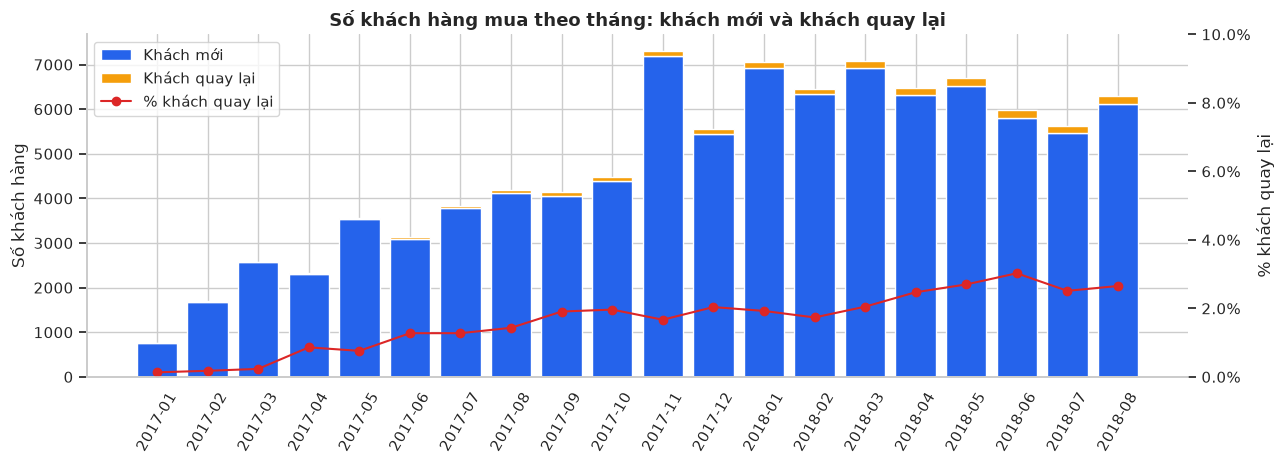

,month,active_customers,new_customers,returning_customers,returning_share,orders,gmv,gmv_mom
0,2017-01,753,752,1,0.001,786,136736.81,NaN
1,2017-02,1690,1687,3,0.002,1715,282977.70,1.070
2,2017-03,2576,2570,6,0.002,2616,425503.89,0.504
3,2017-04,2321,2301,20,0.009,2353,403527.50,-0.052
4,2017-05,3555,3528,27,0.008,3625,581127.99,0.440
5,2017-06,3137,3097,40,0.013,3200,498926.74,-0.141
6,2017-07,3841,3792,49,0.013,3914,574812.07,0.152
7,2017-08,4188,4128,60,0.014,4269,660975.68,0.150
8,2017-09,4141,4062,79,0.019,4214,714189.99,0.081
9,2017-10,4481,4393,88,0.020,4547,764756.03,0.071


In [9]:
# Khách mới của tháng = khách có đơn đầu tiên trong tháng; khách quay lại = khách mua trong tháng nhưng đã mua từ trước.
# (Khách vừa mua đơn đầu vừa mua thêm trong cùng tháng được tính là khách mới -> không đếm trùng.)
growth = q(f"""
SELECT purchase_month,
       count(DISTINCT customer_key)                              AS active_customers,
       count(DISTINCT customer_key) FILTER (WHERE order_seq = 1) AS new_customers,
       count(*)                                                  AS orders,
       sum(gmv)                                                  AS gmv
FROM orders_valid WHERE {P.in_period}
GROUP BY 1 ORDER BY 1""")
growth["returning_customers"] = growth.active_customers - growth.new_customers
growth["returning_share"] = growth.returning_customers / growth.active_customers
growth["gmv_mom"] = growth.gmv.pct_change()
growth["month"] = growth.purchase_month.dt.strftime("%Y-%m")

fig, ax = plt.subplots(figsize=(13, 4.8))
ax.bar(growth.month, growth.new_customers, color=C_MAIN, label="Khách mới")
ax.bar(growth.month, growth.returning_customers, bottom=growth.new_customers, color=C_ACCENT, label="Khách quay lại")
ax.set_title("Số khách hàng mua theo tháng: khách mới và khách quay lại")
ax.set_ylabel("Số khách hàng")
ax.tick_params(axis="x", rotation=60)
ax2 = ax.twinx()
ax2.plot(growth.month, growth.returning_share, color=C_BAD, marker="o", lw=1.5, label="% khách quay lại")
pct_axis(ax2); ax2.grid(False); ax2.set_ylim(0, max(0.1, growth.returning_share.max() * 1.3)); ax2.set_ylabel("% khách quay lại")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left")
plt.tight_layout(); plt.show()

growth[["month", "active_customers", "new_customers", "returning_customers", "returning_share", "orders", "gmv", "gmv_mom"]].round(3)

In [10]:
peak = growth.loc[growth.new_customers.idxmax()]
year, mon = growth.purchase_month.dt.year, growth.purchase_month.dt.month
prev_h1 = growth[(year == P.year_prev) & (mon <= 6)]      # 6 tháng đầu năm trước
cur_year = growth[year == P.year_cur]
peak_cur = cur_year.loc[cur_year.new_customers.idxmax()]
min_cur = cur_year.loc[cur_year.new_customers.idxmin()]
last = growth.iloc[-1]
new_share = 1 - growth.returning_share

print("=== Tỷ trọng khách mới / khách quay lại ===")
print(f"Tỷ lệ khách mới mỗi tháng               : {new_share.min():.1%} – {new_share.max():.1%}")
print(f"Tỷ lệ khách quay lại TB 6 tháng đầu {P.year_prev}: {prev_h1.returning_share.mean():.2%}")
print(f"Tỷ lệ khách quay lại TB năm {P.year_cur}        : {cur_year.returning_share.mean():.2%}")

print("=== Tháng có nhiều khách mới nhất (toàn kỳ) ===")
print(f"Tháng {peak.month}: {int(peak.new_customers):,} khách mới | "
      f"GMV {peak.gmv:,.0f} | GMV so với tháng trước {peak.gmv_mom:+.1%}")

print(f"=== Năm {P.year_cur} ===")
print(f"Khách mới/tháng thấp nhất: {int(min_cur.new_customers):,} ({min_cur.month})")
print(f"Khách mới/tháng cao nhất : {int(peak_cur.new_customers):,} ({peak_cur.month})")
print(f"Tháng cuối kỳ {last.month}: {int(last.new_customers):,} khách mới "
      f"-> thấp hơn đỉnh {P.year_cur} {1 - last.new_customers / peak_cur.new_customers:.1%}")

=== Tỷ trọng khách mới / khách quay lại ===
Tỷ lệ khách mới mỗi tháng               : 97.0% – 99.9%
Tỷ lệ khách quay lại TB 6 tháng đầu 2017: 0.57%
Tỷ lệ khách quay lại TB năm 2018        : 2.38%
=== Tháng có nhiều khách mới nhất (toàn kỳ) ===
Tháng 2017-11: 7,190 khách mới | GMV 1,171,920 | GMV so với tháng trước +53.2%
=== Năm 2018 ===
Khách mới/tháng thấp nhất: 5,473 (2018-07)
Khách mới/tháng cao nhất : 6,930 (2018-03)
Tháng cuối kỳ 2018-08: 6,127 khách mới -> thấp hơn đỉnh 2018 11.6%


> **🔎 Kết quả chính**
> - Mỗi tháng **97,0–99,9% khách mua là khách mới**. Tỷ lệ khách quay lại có tăng (TB 0,57% ở 6 tháng đầu 2017 → 2,38% năm 2018) nhưng vẫn rất nhỏ.
> - Đỉnh khách mới là **11/2017 (7.190 khách, Black Friday)**. Năm 2018 khách mới / tháng chững: cao nhất 6.930 (03/2018), thấp nhất 5.473 (07/2018); 08/2018 thấp hơn đỉnh 2018 11,6% → động cơ tăng trưởng duy nhất đang chậm lại.

## 3. Phân khúc khách hàng RFM
Cả ba chiều đều chấm **1–5**:
- **R** (số ngày từ lần mua cuối) và **M** (tổng chi tiêu): theo **ngưỡng ngũ phân vị** (khách cùng giá trị luôn cùng điểm → ổn định giữa các lần chạy).
- **F** (số đơn hợp lệ): ngũ phân vị của F đều bằng 1 (≈97% khách chỉ mua 1 lần), nên không cắt theo phân vị được →
  dùng **ngưỡng cố định theo số đơn**: F1 = 1 đơn, F2 = 2 đơn, F3 = 3 đơn, F4 = 4 đơn, F5 = ≥ 5 đơn.
  Các mức F3–F5 rất ít khách nhưng vẫn giữ riêng để mã RFM (vd. `545`) đúng chuẩn 5×5×5 và tách được nhóm khách mua nhiều lần nhất.

| Phân khúc | Quy tắc | Ý nghĩa hành động |
|---|---|---|
| Champions | F ≥ 2 và R ≥ 4 | Mua lại & mới mua gần đây → chương trình VIP/thành viên |
| Loyal – cần giữ chân | F ≥ 2 và R ≤ 3 | Từng mua lại nhưng lâu không quay lại → win-back ưu tiên |
| Khách mới | F = 1, R ≥ 4 | Mới mua lần đầu gần đây → kích hoạt đơn thứ 2 (cross-sell, freeship theo ngưỡng) |
| Cần nuôi dưỡng | F = 1, R = 3 | Đã một thời gian chưa quay lại → email/remarketing |
| Giá trị cao sắp mất | F = 1, R ≤ 2, M ≥ 4 | Chi nhiều nhưng lâu không mua → ưu đãi win-back |
| Đã rời bỏ | F = 1, R ≤ 2, M ≤ 3 | Giá trị thấp, lâu không mua → chi phí thấp nhất |

Bảng `customer_rfm` và quy tắc phân khúc do `create_customer_rfm()` của `common/rfm.py` tạo, dùng chung với `01_executive_overview` §3. Ngưỡng R, M, F cụ thể được in ra ở cuối phần này.

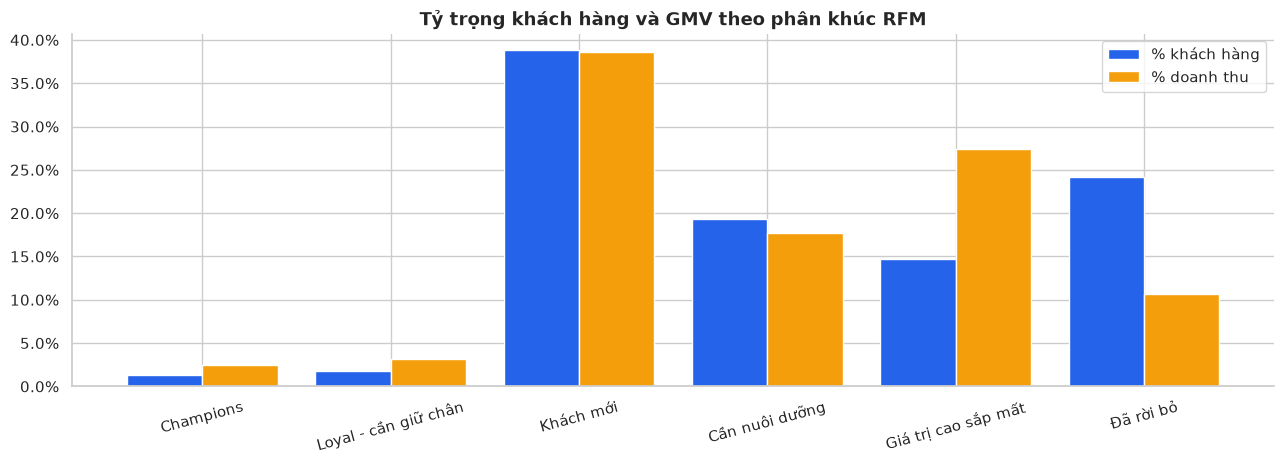

,segment,customers,gmv,avg_recency,avg_frequency,avg_monetary,customers_share,gmv_share
0,Champions,1216,388708.09,97.285,2.16,319.661,0.013,0.025
1,Loyal - cần giữ chân,1614,483473.45,329.310,2.08,299.550,0.017,0.031
2,Khách mới,36342,5993550.07,98.657,1.00,164.921,0.388,0.386
3,Cần nuôi dưỡng,18117,2753710.68,229.347,1.00,151.996,0.193,0.177
4,Giá trị cao sắp mất,13738,4258923.76,402.838,1.00,310.010,0.147,0.274
5,Đã rời bỏ,22637,1647640.36,403.672,1.00,72.785,0.242,0.106


In [11]:
rfm = create_customer_rfm()   # bảng customer_rfm: recency_days, frequency, monetary, R, F, M, rfm_code, segment

seg = q("""
SELECT segment, count(*) AS customers, sum(monetary) AS gmv,
       avg(recency_days) AS avg_recency, avg(frequency) AS avg_frequency, avg(monetary) AS avg_monetary
FROM customer_rfm GROUP BY 1""")
seg = add_share(ordered(seg, "segment", SEG_ORDER, drop_missing=True), "customers", "gmv")

fig, ax = plt.subplots(figsize=(13, 4.8))
grouped_bar(ax, seg.segment, {"% khách hàng": (seg.customers_share, C_MAIN), "% doanh thu": (seg.gmv_share, C_ACCENT)})
ax.tick_params(axis="x", rotation=15); pct_axis(ax)
ax.set_title("Tỷ trọng khách hàng và GMV theo phân khúc RFM")
plt.tight_layout(); plt.show()
seg.round(3)

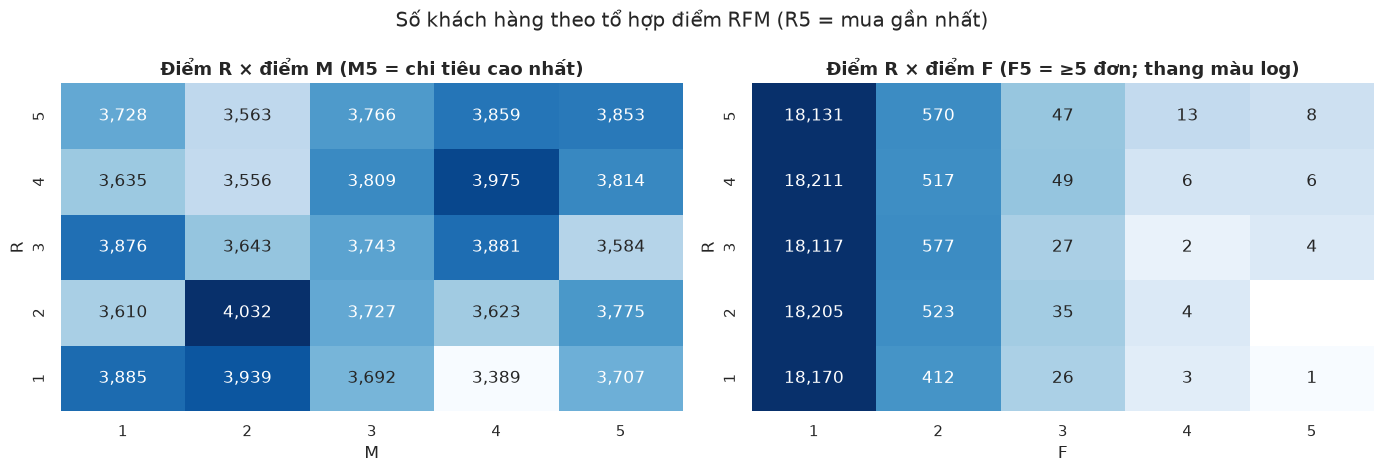

,dim,score,min_value,max_value,customers
0,F,1,1.00,1.00,90834
1,F,2,2.00,2.00,2599
2,F,3,3.00,3.00,184
3,F,4,4.00,4.00,28
4,F,5,5.00,16.00,19
5,M,1,9.59,55.31,18734
6,M,2,55.32,87.41,18733
7,M,3,87.42,133.05,18737
8,M,4,133.06,209.15,18727
9,M,5,209.16,13664.08,18733


In [12]:
# R × F dùng thang log (LogNorm) để các ô F3-F5 rất ít khách vẫn nhìn thấy
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, col, title, norm in [(axes[0], "M", "Điểm R × điểm M (M5 = chi tiêu cao nhất)", None),
                             (axes[1], "F", "Điểm R × điểm F (F5 = ≥5 đơn; thang màu log)", LogNorm(vmin=1))]:
    grid = q(f'SELECT R AS "R", {col} AS "{col}", count(*) AS customers FROM customer_rfm GROUP BY 1, 2')
    gp = (grid.pivot(index="R", columns=col, values="customers")
              .reindex(index=[5, 4, 3, 2, 1], columns=[1, 2, 3, 4, 5]).fillna(0))
    sns.heatmap(gp, annot=True, fmt=",.0f", cmap="Blues", norm=norm, ax=ax, cbar=False); ax.grid(False)
    ax.set_title(title)
fig.suptitle("Số khách hàng theo tổ hợp điểm RFM (R5 = mua gần nhất)")
plt.tight_layout(); plt.show()

# Ngưỡng thực tế của từng điểm R / F / M
rfm_range = pd.concat([
    q(f"""SELECT '{d}' AS dim, {d} AS score, min({c}) AS min_value, max({c}) AS max_value, count(*) AS customers
          FROM customer_rfm GROUP BY 1, 2""")
    for d, c in [("R", "recency_days"), ("F", "frequency"), ("M", "monetary")]
]).sort_values(["dim", "score"]).reset_index(drop=True)
rfm_range.round(2)

> **🔎 Kết quả chính**
> - **Khách mới** là nhóm lớn nhất: 38,8% khách → 38,6% doanh thu; cần kích hoạt đơn thứ 2 trước khi trôi sang nhóm sắp mất (§14).
> - **Giá trị cao sắp mất**: 14,7% khách nhưng **27,4% doanh thu** (≈310 BRL / khách, gần gấp đôi Khách mới ≈165 BRL) → ưu tiên win-back.
> - Khách trung thành (Champions + Loyal) chỉ 3,0% khách, 5,6% doanh thu; **Đã rời bỏ** 24,2% khách nhưng chỉ 10,6% doanh thu → không nên tốn ngân sách giữ chân.
> - Ngưỡng Recency hiện tại: R5 ≤ 103 ngày (~3 tháng), R4 ≤ 186 ngày (~6 tháng), R3 ≤ 276 ngày (~9 tháng). Phân khúc khớp 100% `dim_customer_profile` của Gold (§15).

## 4. Thời điểm mua sắm — khách mua vào lúc nào?

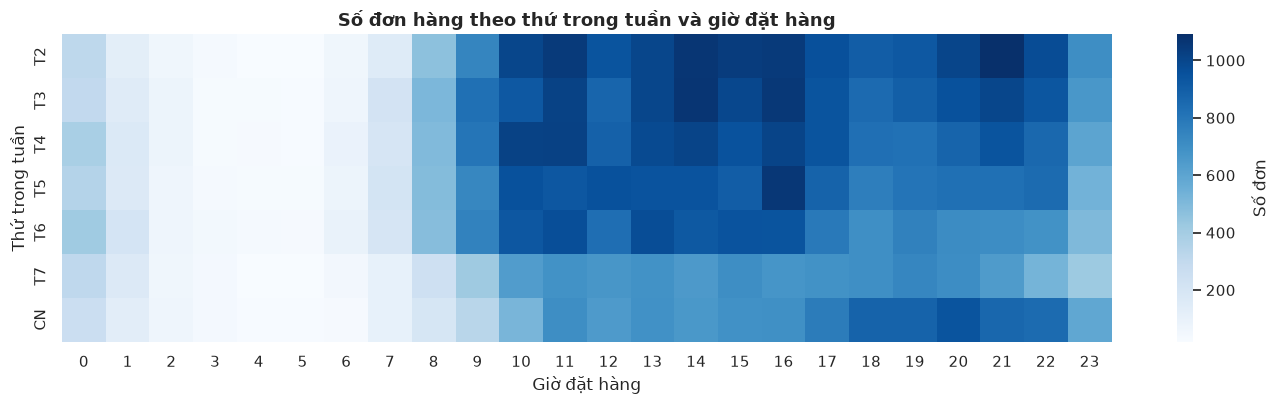

In [13]:
dh = q(f"SELECT dow, purchase_hour, count(*) AS orders FROM orders_valid WHERE {P.in_period} GROUP BY 1, 2")
heat = dh.pivot(index="dow", columns="purchase_hour", values="orders").fillna(0).sort_index()
heat.index = [DOW_LABELS[i - 1] for i in heat.index]
fig, ax = plt.subplots(figsize=(14, 4.2))
sns.heatmap(heat, cmap="Blues", ax=ax, cbar_kws={"label": "Số đơn"}); ax.grid(False)
ax.set_title("Số đơn hàng theo thứ trong tuần và giờ đặt hàng"); ax.set_xlabel("Giờ đặt hàng"); ax.set_ylabel("Thứ trong tuần")
plt.tight_layout(); plt.show()

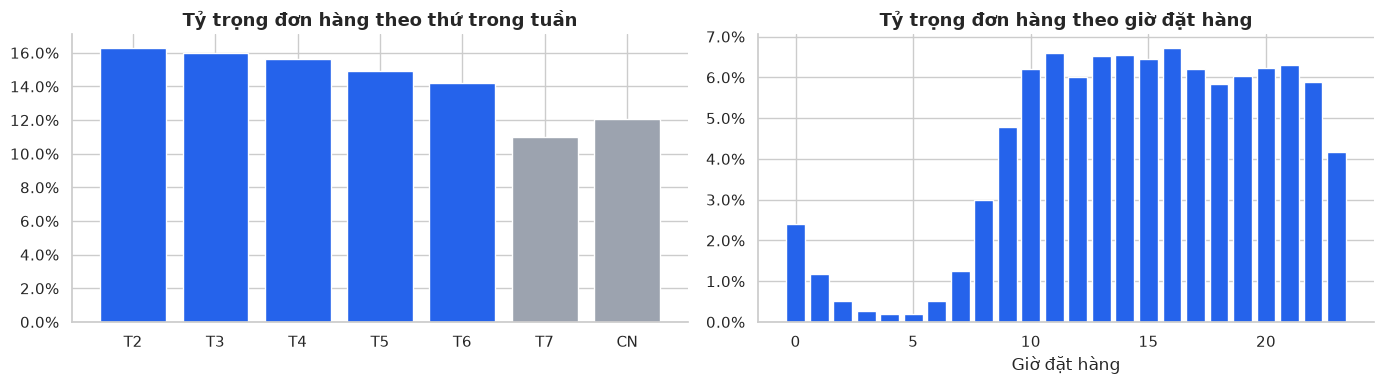

Tỷ trọng theo buổi:
 daypart
Đêm (0-5h)         4.8%
Sáng (6-11h)      22.3%
Chiều (12-17h)    38.5%
Tối (18-23h)      34.5%


,dow,orders,aov,orders_share
0,T2,15717,161.796,0.163
1,T3,15421,159.988,0.160
2,T4,15076,159.539,0.156
3,T5,14391,159.802,0.149
4,T6,13718,162.758,0.142
5,T7,10584,162.120,0.110
6,CN,11620,155.869,0.120


In [14]:
by_dow = add_share(q(f"""SELECT dow, count(*) AS orders, avg(gmv) AS aov
                         FROM orders_valid WHERE {P.in_period} GROUP BY 1 ORDER BY 1"""), "orders")
by_hour = add_share(q(f"""SELECT purchase_hour, count(*) AS orders, avg(gmv) AS aov
                          FROM orders_valid WHERE {P.in_period} GROUP BY 1 ORDER BY 1"""), "orders")

def daypart(h):
    return "Đêm (0-5h)" if h < 6 else "Sáng (6-11h)" if h < 12 else "Chiều (12-17h)" if h < 18 else "Tối (18-23h)"
by_daypart = by_hour.assign(daypart=by_hour.purchase_hour.map(daypart)).groupby("daypart", sort=False)["orders_share"].sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar([DOW_LABELS[i - 1] for i in by_dow.dow], by_dow.orders_share,
            color=[C_MAIN if d < 6 else C_GREY for d in by_dow.dow])
axes[0].set_title("Tỷ trọng đơn hàng theo thứ trong tuần"); pct_axis(axes[0])
axes[1].bar(by_hour.purchase_hour, by_hour.orders_share, color=C_MAIN)
axes[1].set_title("Tỷ trọng đơn hàng theo giờ đặt hàng"); axes[1].set_xlabel("Giờ đặt hàng"); pct_axis(axes[1])
plt.tight_layout(); plt.show()
print("Tỷ trọng theo buổi:\n", by_daypart.map("{:.1%}".format).to_string())
by_dow.assign(dow=[DOW_LABELS[i - 1] for i in by_dow.dow]).round(3)

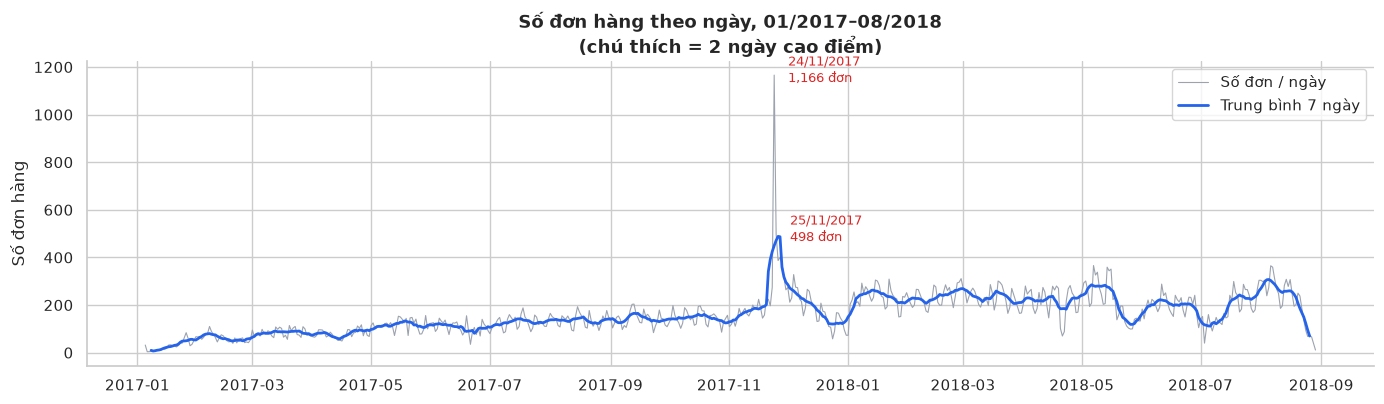

purchase_date  orders   ma7  vs_ma7
   2017-11-24    1166 449.6    2.59
   2017-11-25     498 471.1    1.06
   2017-11-27     400 486.9    0.82
   2017-11-26     387 488.4    0.79
   2017-11-28     375 359.4    1.04


In [15]:
daily = q("SELECT purchase_date, count(*) AS orders, sum(gmv) AS gmv FROM orders_valid GROUP BY 1 ORDER BY 1")
daily = daily[(daily.purchase_date >= pd.Timestamp(P.m_start)) &
              (daily.purchase_date < pd.Timestamp(P.m_end) + pd.offsets.MonthBegin(1))].copy()
daily["ma7"] = daily.orders.rolling(7, center=True).mean()
top_days = daily.nlargest(5, "orders").assign(vs_ma7=lambda d: d.orders / d.ma7)

fig, ax = plt.subplots(figsize=(14, 4.2))
ax.plot(daily.purchase_date, daily.orders, color=C_GREY, lw=0.8, label="Số đơn / ngày")
ax.plot(daily.purchase_date, daily.ma7, color=C_MAIN, lw=2, label="Trung bình 7 ngày")
for _, r in top_days.head(2).iterrows():
    ax.annotate(f"{r.purchase_date:%d/%m/%Y}\n{r.orders:,.0f} đơn", (r.purchase_date, r.orders),
                xytext=(10, -5), textcoords="offset points", fontsize=9, color=C_BAD)
ax.set_title(f"Số đơn hàng theo ngày, {P.label_trend}\n(chú thích = 2 ngày cao điểm)"); ax.set_ylabel("Số đơn hàng"); ax.legend()
plt.tight_layout(); plt.show()
print(top_days[["purchase_date", "orders", "ma7", "vs_ma7"]].round({"ma7": 1, "vs_ma7": 2}).to_string(index=False))

> **🔎 Kết quả chính**
> - Khách mua nhiều nhất **đầu tuần**: T2 16,3%, T3 16,0% số đơn; thấp nhất T7 (11,0%) và CN (12,0%).
> - Theo buổi: chiều (12–17h) 38,5%, tối (18–23h) 34,5%, sáng 22,3%, đêm 4,8% → khung giờ vàng cho thông báo / quảng cáo là **chiều và tối ngày thường**.
> - AOV theo thứ chỉ dao động 156–163 BRL → thời điểm ảnh hưởng **số đơn**, không ảnh hưởng giá trị giỏ hàng.
> - Ngày **24/11/2017 (Black Friday) có 1.166 đơn**, gấp 2,6 lần trung bình 7 ngày — đỉnh lớn nhất trong kỳ; các ngày sau đó trở lại bình thường ngay.

## 5. Giỏ hàng & mức chi tiêu

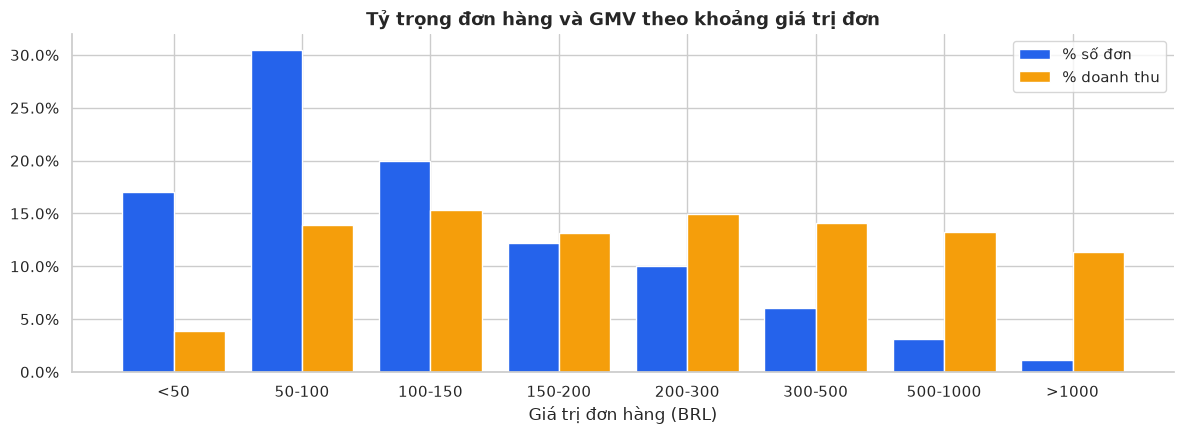

Giá trị đơn — P25/P50/P75/P90/P99: [61.9, 105.3, 176.8, 307.4, 1057.3]


,value_band,orders,gmv,freight_share,avg_installments,orders_share,gmv_share
0,<50,16506,608555.73,0.355,1.520,0.170,0.039
1,50-100,29537,2164221.06,0.230,2.274,0.305,0.139
2,100-150,19290,2377975.41,0.169,2.994,0.199,0.153
3,150-200,11794,2036460.24,0.149,3.479,0.122,0.131
4,200-300,9680,2318791.76,0.131,4.090,0.100,0.149
5,300-500,5862,2189756.91,0.107,4.802,0.061,0.141
6,500-1000,3029,2061419.32,0.076,5.874,0.031,0.133
7,>1000,1119,1768825.98,0.053,6.575,0.012,0.114


In [16]:
VALUE_BINS, VALUE_LAST = band_bins(GOLD.ORDER_VALUE_BANDS)   # khoảng giá trị đơn (BRL), giống order_value_band của Gold
VALUE_LABELS = band_order(GOLD.ORDER_VALUE_BANDS)

bands = q(f"""
SELECT {band_sql("gmv", VALUE_BINS, VALUE_LAST)} AS value_band,
       count(*) AS orders, sum(gmv) AS gmv,
       sum(freight_value) / sum(gmv) AS freight_share,
       avg(installments) AS avg_installments
FROM orders_valid GROUP BY 1""")
bands = add_share(ordered(bands, "value_band", VALUE_LABELS, drop_missing=True), "orders", "gmv")

fig, ax = plt.subplots(figsize=(12, 4.5))
grouped_bar(ax, bands.value_band, {"% số đơn": (bands.orders_share, C_MAIN), "% doanh thu": (bands.gmv_share, C_ACCENT)})
pct_axis(ax); ax.set_title("Tỷ trọng đơn hàng và GMV theo khoảng giá trị đơn"); ax.set_xlabel("Giá trị đơn hàng (BRL)")
plt.tight_layout(); plt.show()

qs = scalar(f"SELECT {quantile_sql('gmv', [0.25, 0.5, 0.75, 0.9, 0.99])} FROM orders_valid")
print("Giá trị đơn — P25/P50/P75/P90/P99:", [round(v, 1) for v in qs])
bands.round(3)

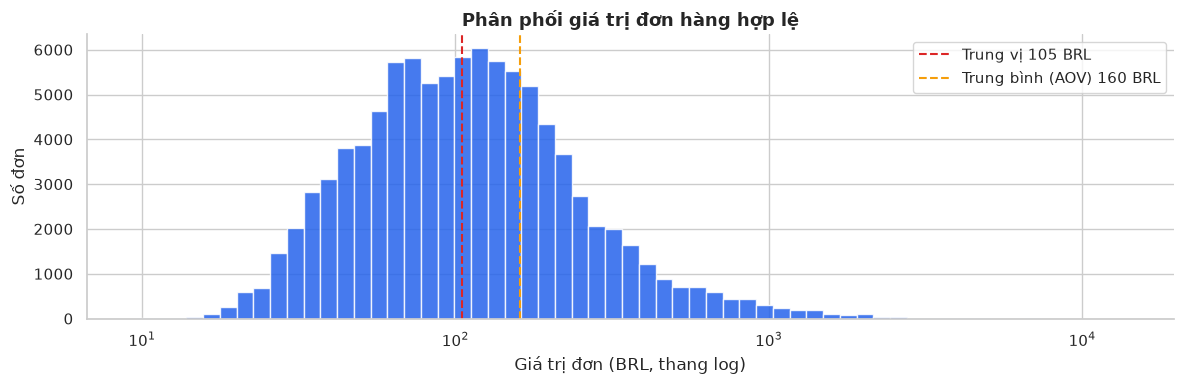

Độ lệch (skewness): 9.3; % đơn > 3 × trung vị: 9.4%


In [17]:
# Phân phối giá trị đơn (thang log): trung vị và đuôi dài
vals = q("SELECT gmv FROM orders_valid").gmv
fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(vals, bins=np.logspace(np.log10(max(vals.min(), 1)), np.log10(vals.max()), 60), color=C_MAIN, alpha=0.85)
ax.set_xscale("log"); ax.axvline(vals.median(), color=C_BAD, ls="--", label=f"Trung vị {vals.median():,.0f} BRL")
ax.axvline(vals.mean(), color=C_ACCENT, ls="--", label=f"Trung bình (AOV) {vals.mean():,.0f} BRL")
ax.set_xlabel("Giá trị đơn (BRL, thang log)"); ax.set_ylabel("Số đơn"); ax.legend()
ax.set_title("Phân phối giá trị đơn hàng hợp lệ")
plt.tight_layout(); plt.show()
print(f"Độ lệch (skewness): {vals.skew():.1f}; % đơn > 3 × trung vị: {(vals > 3 * vals.median()).mean():.1%}")

% đơn có >1 sản phẩm khác nhau: 3.3% | >1 ngành hàng: 0.8% | >1 người bán: 1.3%


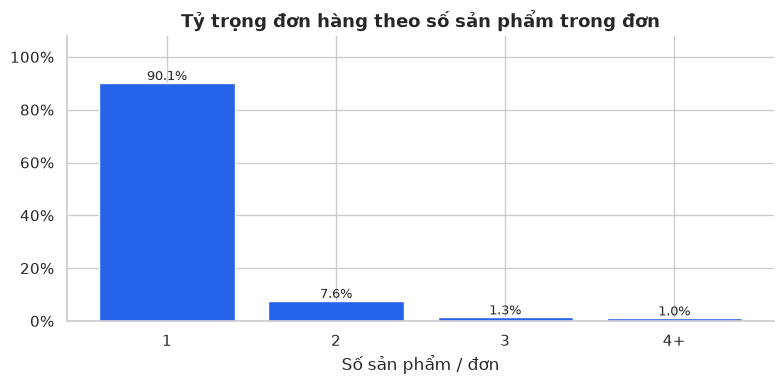

In [18]:
ipo = add_share(q("""
SELECT CASE WHEN n_items >= 4 THEN '4+' ELSE CAST(n_items AS VARCHAR) END AS n_items_b,
       count(*) AS orders, avg(gmv) AS aov
FROM orders_valid GROUP BY 1 ORDER BY 1"""), "orders")
multi = q("""
SELECT avg(CAST(n_products > 1 AS INTEGER))   AS multi_product,
       avg(CAST(n_categories > 1 AS INTEGER)) AS multi_category,
       avg(CAST(n_sellers > 1 AS INTEGER))    AS multi_seller
FROM orders_valid""").iloc[0]
print(f"% đơn có >1 sản phẩm khác nhau: {multi.multi_product:.1%} | >1 ngành hàng: {multi.multi_category:.1%} "
      f"| >1 người bán: {multi.multi_seller:.1%}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(ipo.n_items_b, ipo.orders_share, color=C_MAIN)
for i, r in enumerate(ipo.itertuples()):
    ax.text(i, r.orders_share, f"{r.orders_share:.1%}", ha="center", va="bottom", fontsize=9)
ax.set_title("Tỷ trọng đơn hàng theo số sản phẩm trong đơn"); ax.set_xlabel("Số sản phẩm / đơn"); pct_axis(ax)
ax.set_ylim(0, ipo.orders_share.max() * 1.2)
plt.tight_layout(); plt.show()

> **🔎 Kết quả chính**
> - Giá trị đơn lệch phải mạnh (skewness 9,3): trung vị **105 BRL**, 75% đơn dưới 177 BRL, nhưng P99 ≈ 1.057 BRL.
> - Khoảng 50–100 BRL nhiều đơn nhất (30,5% đơn) nhưng chỉ 13,9% doanh thu; đơn ≥ 300 BRL chỉ 10,4% số đơn nhưng tạo **38,8% doanh thu**.
> - **Phí ship chiếm 35,5% giá trị đơn < 50 BRL** (5,3% ở đơn > 1.000 BRL) → freeship theo ngưỡng (vd. từ 100 BRL) có thể kích khách gom đơn.
> - **Gần như không có bán chéo**: chỉ 3,3% đơn có > 1 sản phẩm khác nhau, 0,8% đơn > 1 ngành hàng, 1,3% đơn > 1 người bán.

## 6. Hành vi thanh toán

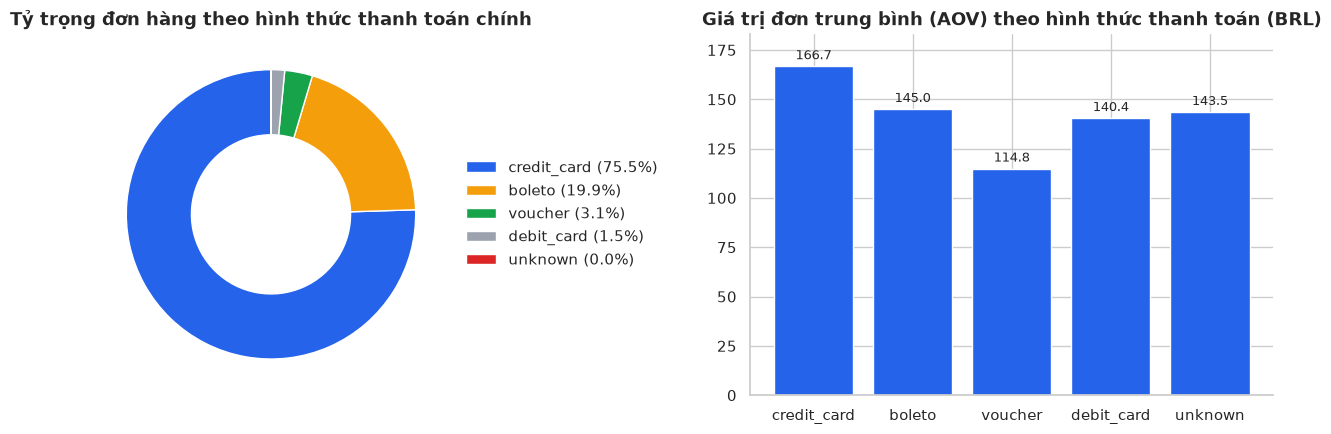

% đơn có dùng voucher (kể cả kết hợp): 3.8% | % đơn dùng >1 hình thức thanh toán: 2.3%


,payment_type,orders,gmv,aov,avg_installments,orders_share,gmv_share
0,credit_card,73104,12184985.67,166.680,3.554,0.755,0.785
1,boleto,19243,2790227.25,145.000,1.000,0.199,0.180
2,voucher,3000,344396.26,114.799,1.146,0.031,0.022
3,debit_card,1469,206253.77,140.404,1.000,0.015,0.013
4,unknown,1,143.46,143.460,NaN,0.000,0.000


In [19]:
pay = add_share(q("""
SELECT payment_type, count(*) AS orders, sum(gmv) AS gmv, avg(gmv) AS aov, avg(installments) AS avg_installments
FROM orders_valid GROUP BY 1 ORDER BY orders DESC"""), "orders", "gmv")
pay_mix = q("SELECT avg(used_voucher) AS voucher, avg(CAST(n_payment_types > 1 AS INTEGER)) AS multi_type FROM orders_valid").iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
wedges, _ = axes[0].pie(pay.orders_share, startangle=90,
                        colors=[C_MAIN, C_ACCENT, C_GOOD, C_GREY, C_BAD][:len(pay)], wedgeprops={"width": 0.45})
axes[0].legend(wedges, [f"{t} ({s:.1%})" for t, s in zip(pay.payment_type, pay.orders_share)],
               loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
axes[0].set_title("Tỷ trọng đơn hàng theo hình thức thanh toán chính")
axes[1].bar(pay.payment_type, pay.aov, color=C_MAIN); axes[1].set_title("Giá trị đơn trung bình (AOV) theo hình thức thanh toán (BRL)")
axes[1].bar_label(axes[1].containers[0], fmt="%.1f", padding=3, fontsize=9); axes[1].margins(y=0.1)
plt.tight_layout(); plt.show()
print(f"% đơn có dùng voucher (kể cả kết hợp): {pay_mix.voucher:.1%} | % đơn dùng >1 hình thức thanh toán: {pay_mix.multi_type:.1%}")
pay.round(3)

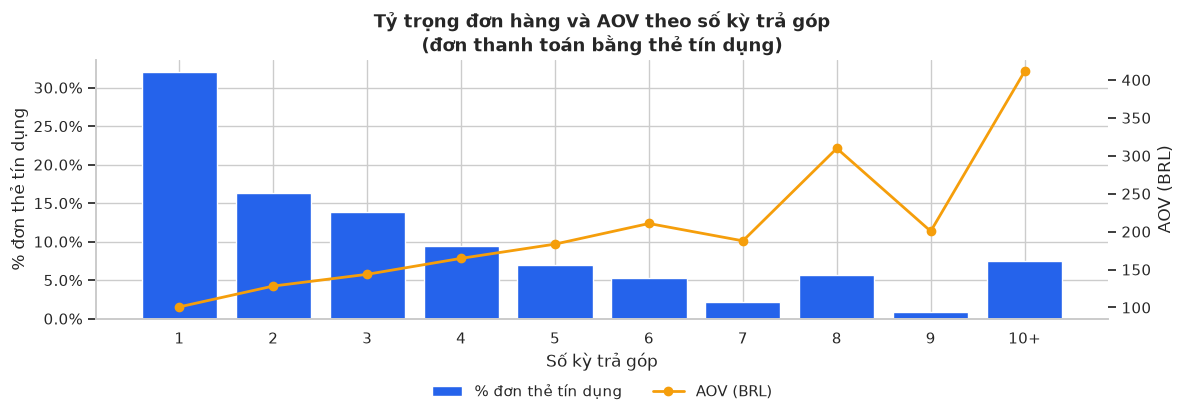

% đơn thẻ tín dụng trả góp (>1 kỳ): 68.0% — chiếm 80.6% doanh thu thẻ


,inst_b,orders,aov,gmv,orders_share,gmv_share,label
0,1,23424,100.802,2361184.37,0.320,0.194,1
1,2,11965,128.253,1534551.30,0.164,0.126,2
2,3,10110,143.740,1453209.89,0.138,0.119,3
3,4,6862,164.773,1130674.10,0.094,0.093,4
4,5,5081,183.549,932610.37,0.070,0.077,5
5,6,3817,210.719,804316.20,0.052,0.066,6
6,7,1585,187.833,297715.80,0.022,0.024,7
7,8,4130,309.781,1279395.03,0.056,0.105,8
8,9,616,200.503,123509.93,0.008,0.010,9
9,10,5514,411.284,2267818.68,0.075,0.186,10+


In [20]:
inst = add_share(q("""
SELECT least(greatest(installments, 1), 10) AS inst_b, count(*) AS orders, avg(gmv) AS aov, sum(gmv) AS gmv
FROM orders_valid WHERE payment_type = 'credit_card'
GROUP BY 1 ORDER BY 1"""), "orders", "gmv")
inst["label"] = inst.inst_b.astype(int).astype(str).replace({"10": "10+"})

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(inst.label, inst.orders_share, color=C_MAIN, label="% đơn thẻ tín dụng"); pct_axis(ax)
ax2 = ax.twinx(); ax2.plot(inst.label, inst.aov, color=C_ACCENT, marker="o", lw=2, label="AOV (BRL)"); ax2.grid(False)
ax.set_title("Tỷ trọng đơn hàng và AOV theo số kỳ trả góp\n(đơn thanh toán bằng thẻ tín dụng)"); ax.set_xlabel("Số kỳ trả góp")
ax.set_ylabel("% đơn thẻ tín dụng"); ax2.set_ylabel("AOV (BRL)")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)
plt.tight_layout(); plt.show()
inst_multi = inst[inst.inst_b > 1]
print(f"% đơn thẻ tín dụng trả góp (>1 kỳ): {inst_multi.orders_share.sum():.1%} — chiếm {inst_multi.gmv_share.sum():.1%} doanh thu thẻ")
inst.round(3)

> **🔎 Kết quả chính**
> - **Thẻ tín dụng thống trị**: 75,5% số đơn, 78,5% doanh thu, AOV 167 BRL. Boleto 19,9% đơn; voucher 3,1%; thẻ ghi nợ 1,5%.
> - **68,0% đơn thẻ tín dụng là trả góp**, chiếm 80,6% doanh thu thẻ. AOV tăng mạnh theo số kỳ: 1 kỳ ≈ 101 BRL → 10+ kỳ ≈ **411 BRL**; có "đỉnh" số đơn ở 8 kỳ và 10+ kỳ (mốc trả góp phổ biến).
> - → Trả góp không lãi là đòn bẩy cho đơn giá trị cao; kênh khuyến mãi nên đi qua thẻ tín dụng.

## 7. Mua lặp lại — khách có quay lại không?

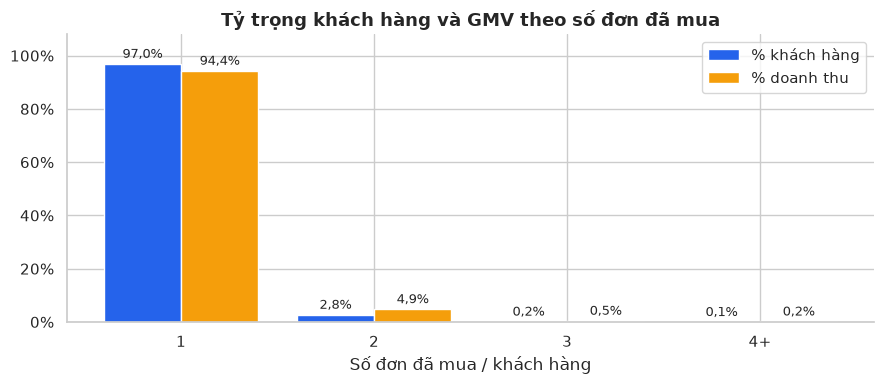

In [21]:
freq = add_share(q("""
SELECT CASE WHEN frequency >= 4 THEN '4+' ELSE CAST(frequency AS VARCHAR) END AS f,
       count(*) AS customers, sum(monetary) AS gmv, avg(monetary) AS clv
FROM cust_base GROUP BY 1 ORDER BY 1"""), "customers", "gmv")

fig, ax = plt.subplots(figsize=(9, 4))
grouped_bar(ax, freq.f, {"% khách hàng": (freq.customers_share, C_MAIN), "% doanh thu": (freq.gmv_share, C_ACCENT)})
for bars in ax.containers:  # ghi giá trị trên cột để đọc được cả các cột rất thấp
    ax.bar_label(bars, labels=[pct(v, 1) for v in bars.datavalues], padding=2, fontsize=9)
ax.set_xlabel("Số đơn đã mua / khách hàng"); ax.set_ylim(0, 1.08); pct_axis(ax, decimals=0)
ax.set_title("Tỷ trọng khách hàng và GMV theo số đơn đã mua")
plt.tight_layout(); plt.show()

Khách có đơn thứ 2: 2,830 | Trung vị thời gian tới đơn thứ 2 (bỏ cùng ngày): 75 ngày


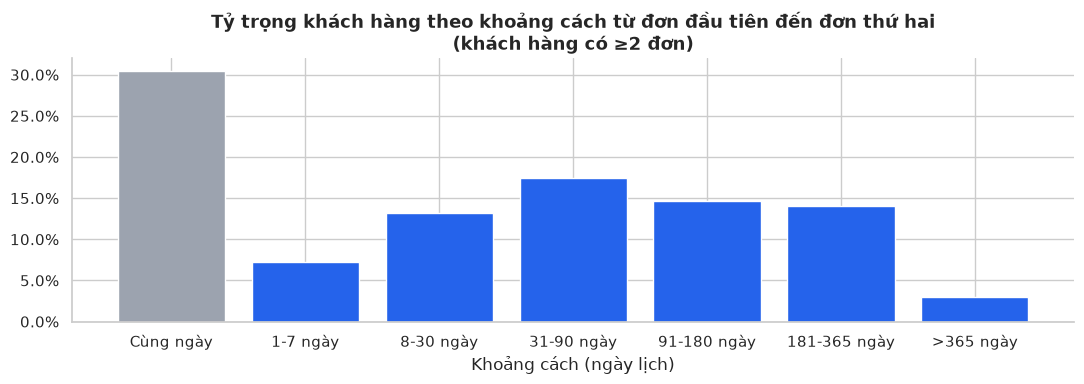

In [22]:
GAP_BINS, GAP_LAST = band_bins(GOLD.GAP_BANDS)   # khoảng cách tới đơn thứ 2, giống gap_bucket của Gold
GAP_ORDER = band_order(GOLD.GAP_BANDS)
t2 = q(f"""
SELECT {band_sql("days_to_2nd_order", GAP_BINS, GAP_LAST, upper_inclusive=True)} AS bucket, count(*) AS customers
FROM cust_base WHERE days_to_2nd_order IS NOT NULL GROUP BY 1""")
t2 = add_share(ordered(t2, "bucket", GAP_ORDER, drop_missing=True), "customers")
gap = q(f"""
SELECT count(*) AS n_2nd,
       {median_sql("days_to_2nd_order", where="days_to_2nd_order >= 1")}               AS median_days,
       avg(CAST(days_to_2nd_order <= 90 AS INTEGER)) FILTER (WHERE days_to_2nd_order >= 1) AS within_90
FROM cust_base WHERE days_to_2nd_order IS NOT NULL""").iloc[0]
print(f"Khách có đơn thứ 2: {gap.n_2nd:,.0f} | Trung vị thời gian tới đơn thứ 2 (bỏ cùng ngày): {gap.median_days:.0f} ngày")

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(t2.bucket, t2.customers_share, color=[C_GREY] + [C_MAIN] * (len(t2) - 1)); pct_axis(ax)
ax.set_title("Tỷ trọng khách hàng theo khoảng cách từ đơn đầu tiên đến đơn thứ hai\n(khách hàng có ≥2 đơn)")
ax.set_xlabel("Khoảng cách (ngày lịch)")
plt.tight_layout(); plt.show()

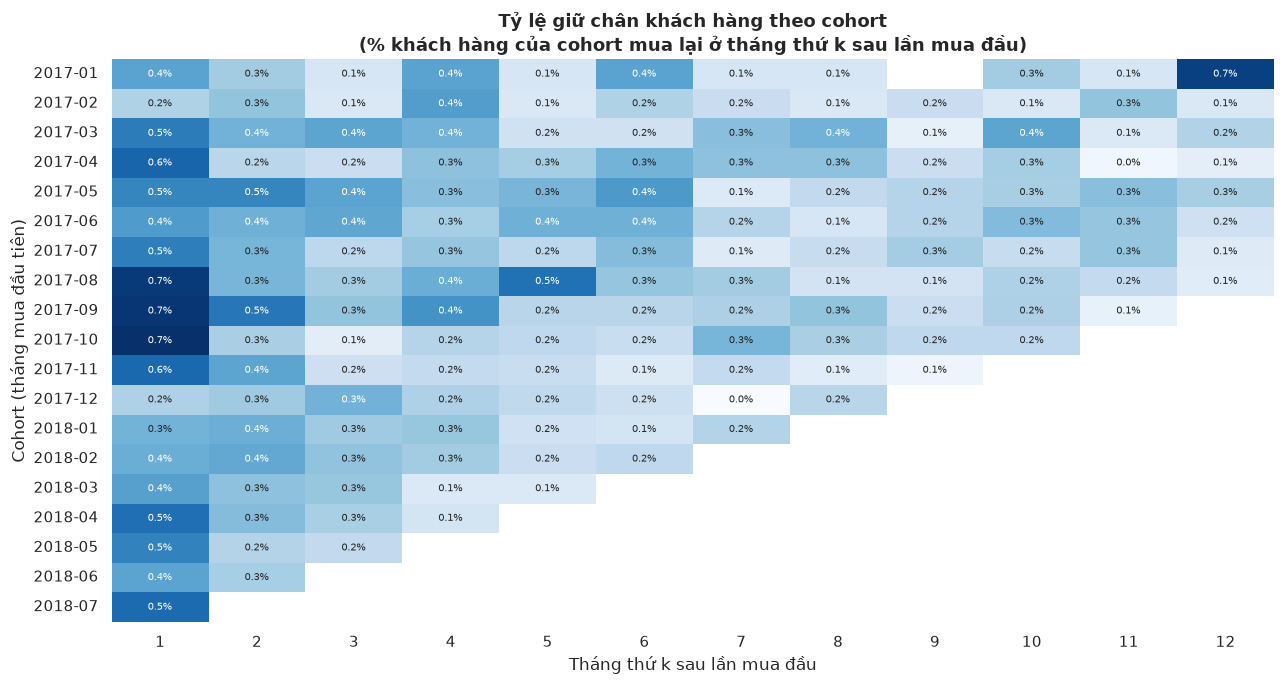

Retention TB tháng 1 / 3 / 6: M1: 0.48%, M3: 0.25%, M6: 0.25%


In [23]:
coh = q(f"""
SELECT c.cohort_month,
       date_diff('month', c.cohort_month, o.purchase_month) AS month_idx,
       count(DISTINCT o.customer_key) AS customers
FROM orders_valid o JOIN cust_base c ON c.customer_key = o.customer_key
WHERE c.cohort_month BETWEEN DATE '{P.m_start}' AND DATE '{P.m_end}' AND o.purchase_month <= DATE '{P.m_end}'
GROUP BY 1, 2""")
size = coh[coh.month_idx == 0].set_index("cohort_month").customers
coh["retention"] = coh.customers / coh.cohort_month.map(size)
ret = coh[(coh.month_idx >= 1) & (coh.month_idx <= 12)].pivot(index="cohort_month", columns="month_idx", values="retention")
ret.index = pd.to_datetime(ret.index).strftime("%Y-%m")

fig, ax = plt.subplots(figsize=(13, 7))
sns.heatmap(ret, annot=True, fmt=".1%", cmap="Blues", ax=ax, cbar=False, annot_kws={"fontsize": 7}); ax.grid(False)
ax.set_title("Tỷ lệ giữ chân khách hàng theo cohort\n(% khách hàng của cohort mua lại ở tháng thứ k sau lần mua đầu)")
ax.set_xlabel("Tháng thứ k sau lần mua đầu"); ax.set_ylabel("Cohort (tháng mua đầu tiên)")
plt.tight_layout(); plt.show()
print("Retention TB tháng 1 / 3 / 6:", ", ".join(f"M{m}: {ret[m].mean():.2%}" for m in [1, 3, 6] if m in ret))

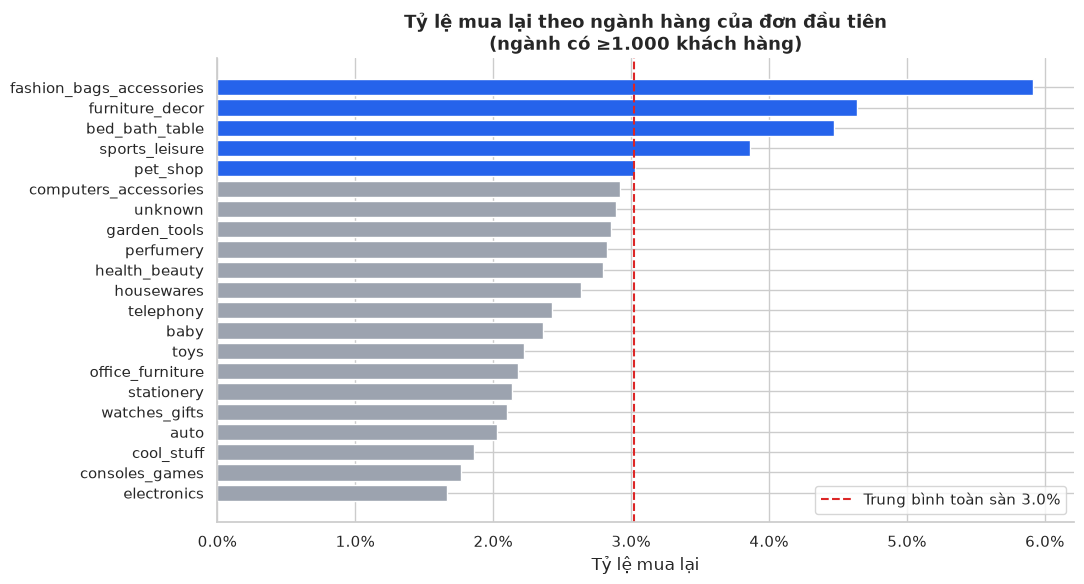

          first_category  customers  repeat_rate
fashion_bags_accessories       1707       0.0592
         furniture_decor       5950       0.0464
          bed_bath_table       8720       0.0447
          sports_leisure       7250       0.0386
                pet_shop       1619       0.0303
   computers_accessories       6328       0.0292
                 unknown       1349       0.0289
            garden_tools       3325       0.0286
               perfumery       3006       0.0283
           health_beauty       8354       0.0280
              housewares       5496       0.0264
               telephony       4032       0.0243
                    baby       2711       0.0236
                    toys       3681       0.0223
        office_furniture       1238       0.0218
              stationery       2197       0.0214
           watches_gifts       5334       0.0210
                    auto       3703       0.0203
              cool_stuff       3497       0.0186
          consoles_g

In [24]:
rep_cat = q("""
SELECT first_category, count(*) AS customers, avg(CAST(is_repeat AS INTEGER)) AS repeat_rate
FROM cust_base GROUP BY 1 HAVING count(*) >= 1000 ORDER BY repeat_rate DESC""")
overall_rr = kc.repeat_rate
fig, ax = plt.subplots(figsize=(11, 6))
r = rep_cat.iloc[::-1]
ax.barh(r.first_category, r.repeat_rate, color=[C_MAIN if v >= overall_rr else C_GREY for v in r.repeat_rate])
ax.axvline(overall_rr, color=C_BAD, ls="--", label=f"Trung bình toàn sàn {overall_rr:.1%}"); pct_axis(ax, "x"); ax.legend()
ax.set_title("Tỷ lệ mua lại theo ngành hàng của đơn đầu tiên\n(ngành có ≥1.000 khách hàng)"); ax.set_xlabel("Tỷ lệ mua lại")
plt.tight_layout()
plt.show()
print(rep_cat.round(4).to_string(index=False))

> **🔎 Kết quả chính**
> - **97% khách chỉ mua 1 lần.** 2.830 khách có đơn thứ hai; bỏ các đơn thứ hai cùng ngày (khách tách đơn), **trung vị 75 ngày** tới đơn thứ hai → cửa sổ nhắc quay lại là 1–3 tháng sau đơn đầu.
> - Giữ chân theo cohort rất thấp: TB **0,48% ở tháng thứ 1**, 0,25% ở tháng 3 và 6 — không cohort nào tạo được nhóm khách trung thành, kể cả cohort Black Friday.
> - Ngành của đơn đầu có liên quan: khách mở đầu bằng **fashion_bags_accessories (5,9%), furniture_decor (4,6%), bed_bath_table (4,5%), sports_leisure (3,9%)** quay lại nhiều hơn mức chung 3,0%; thấp nhất là electronics (1,7%), consoles_games, cool_stuff — hàng mua một lần.

## 8. Mức độ hài lòng
*Câu hỏi: "Khách hàng chấm điểm ra sao? Tỷ lệ khách bất mãn lớn đến đâu?"*

Bảng KPI trải nghiệm tính trên mọi đơn được đặt (kể cả đơn hủy).

In [25]:
kpi = {
    **q('''SELECT count(*) AS total_orders, avg(is_delivered) AS delivered_rate, avg(is_canceled) AS cancel_rate,
                  avg(review_score) AS avg_review_score, avg(is_positive) AS positive_rate, avg(is_negative) AS negative_rate
           FROM order_cx''').iloc[0].to_dict(),
    **q(f'''SELECT avg(delivery_days) AS avg_delivery_days, {median_sql("delivery_days")} AS median_delivery_days,
                  avg(estimated_delivery_days) AS avg_estimated_days, avg(1 - is_late) AS on_time_rate
           FROM delivered''').iloc[0].to_dict(),
    **q('''SELECT count(*) FILTER (WHERE review_score IS NOT NULL) AS reviewed_orders,
                  avg(CAST(review_score IS NOT NULL AS INTEGER)) AS review_rate
           FROM order_cx''').iloc[0].to_dict(),
}
labels = {
    "total_orders": ("Tổng số đơn", "{:,.0f}"),
    "reviewed_orders": ("Số đơn có đánh giá", "{:,.0f}"),
    "review_rate": ("% đơn có đánh giá / tổng đơn", "{:.1%}"),
    "avg_review_score": ("Điểm review TB (1–5)", "{:.2f}"),
    "positive_rate": ("% đơn hài lòng (4–5★)", "{:.1%}"),
    "negative_rate": ("% đơn không hài lòng (1–2★)", "{:.1%}"),
    "on_time_rate": ("% giao đúng hạn", "{:.1%}"),
    "avg_delivery_days": ("Thời gian giao TB (ngày)", "{:.1f}"),
    "median_delivery_days": ("Thời gian giao trung vị (ngày)", "{:.0f}"),
    "avg_estimated_days": ("Thời gian hứa giao TB (ngày)", "{:.1f}"),
    "delivered_rate": ("% đơn giao thành công", "{:.1%}"),
    "cancel_rate": ("% đơn bị hủy", "{:.2%}"),
}
print(pd.DataFrame([(lbl, fmt.format(kpi[key])) for key, (lbl, fmt) in labels.items()], columns=["KPI", "Giá trị"])
      .to_string(index=False))

                           KPI Giá trị
                   Tổng số đơn  98,059
            Số đơn có đánh giá  96,725
  % đơn có đánh giá / tổng đơn   98.6%
          Điểm review TB (1–5)    4.09
         % đơn hài lòng (4–5★)   77.0%
   % đơn không hài lòng (1–2★)   14.7%
               % giao đúng hạn   93.2%
      Thời gian giao TB (ngày)    12.2
Thời gian giao trung vị (ngày)      10
  Thời gian hứa giao TB (ngày)    23.4
         % đơn giao thành công   97.0%
                  % đơn bị hủy   0.64%


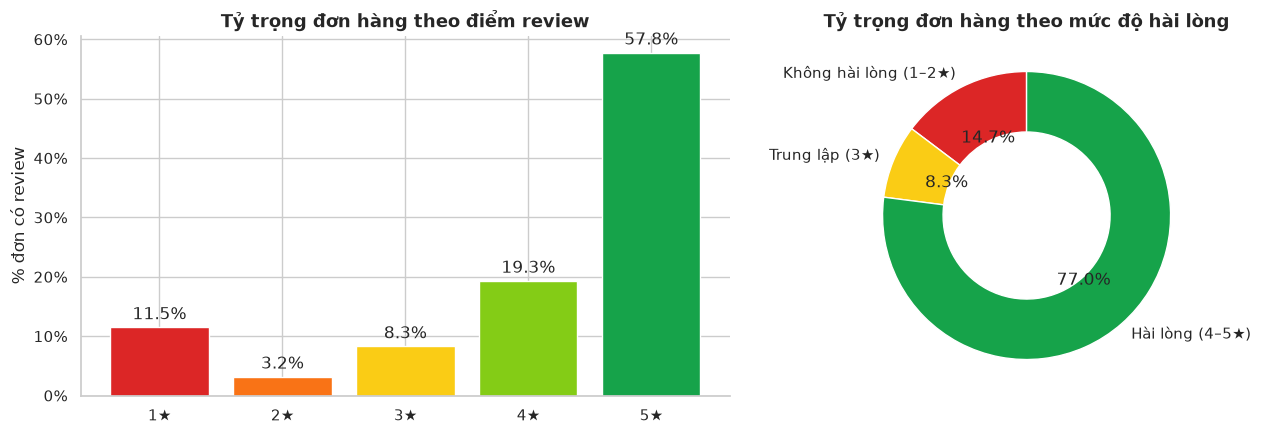

 score_int     n  share
         1 11112  0.115
         2  3067  0.032
         3  8004  0.083
         4 18681  0.193
         5 55861  0.578


In [26]:
score_dist = q("SELECT score_int, count(*) AS n FROM reviewed GROUP BY 1 ORDER BY 1")
score_dist["share"] = score_dist.n / score_dist.n.sum()
sat = q("SELECT satisfaction, count(*) AS n FROM reviewed GROUP BY 1").set_index("satisfaction")["n"]
sat = sat.reindex(["Không hài lòng (1–2★)", "Trung lập (3★)", "Hài lòng (4–5★)"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
bars = ax1.bar(score_dist.score_int.astype(str) + "★", score_dist.share,
               color=[SCORE_COLORS[s] for s in score_dist.score_int])
ax1.bar_label(bars, labels=[f"{v:.1%}" for v in score_dist.share], padding=3)
ax1.set_title("Tỷ trọng đơn hàng theo điểm review"); pct_axis(ax1); ax1.set_ylabel("% đơn có review")
ax2.pie(sat, labels=sat.index, autopct="%1.1f%%", startangle=90, colors=[C_BAD, C_YELLOW, C_GOOD],
        wedgeprops=dict(width=0.42, edgecolor="white"))
ax2.set_title("Tỷ trọng đơn hàng theo mức độ hài lòng")
plt.tight_layout(); plt.show()
print(score_dist.round(3).to_string(index=False))

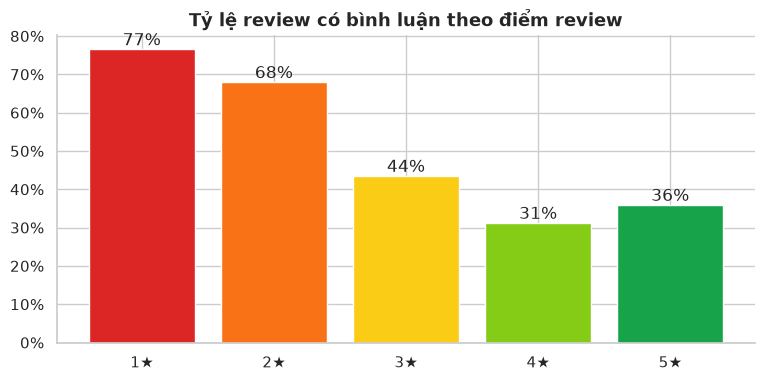

 review_score  comment_rate
            1         0.766
            2         0.680
            3         0.435
            4         0.312
            5         0.359


In [27]:
# Khách có để lại bình luận không? (tính trên từng review — bình luận là tín hiệu cảm xúc mạnh)
comment = q('''SELECT review_score, avg(CAST(review_comment_message IS NOT NULL AS INTEGER)) AS comment_rate
               FROM fact_reviews GROUP BY 1 ORDER BY 1''')
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(comment.review_score.astype(str) + "★", comment.comment_rate,
              color=[SCORE_COLORS[s] for s in comment.review_score])
ax.bar_label(bars, labels=[f"{v:.0%}" for v in comment.comment_rate])
ax.set_title("Tỷ lệ review có bình luận theo điểm review"); pct_axis(ax)
plt.show()
print(comment.round(3).to_string(index=False))

> **🔎 Kết quả chính**
> - Trên mọi đơn được đặt: điểm review TB **4,09**; **77,0%** đơn hài lòng, **14,7%** đơn không hài lòng. Giao hàng "trên giấy" tốt: 93,2% đúng hạn, giao TB 12,2 ngày (trung vị 10) trong khi hứa giao TB 23,4 ngày.
> - Phân phối điểm hai cực: 57,8% đơn 5★, nhưng **1★ (11,5%) cao gấp 3,6 lần 2★ (3,2%)** — khách bất mãn thường chấm thẳng 1★.
> - Khách bất mãn lên tiếng nhiều hơn: **77%** review 1★ và 68% review 2★ có bình luận, so với 31–36% ở nhóm 4–5★ → bình luận là nguồn tốt để đọc nguyên nhân (chưa khai thác trong EDA này).

## 9. Xu hướng trải nghiệm theo thời gian
*Câu hỏi: "Trải nghiệm đang tốt lên hay xấu đi theo thời gian?"*

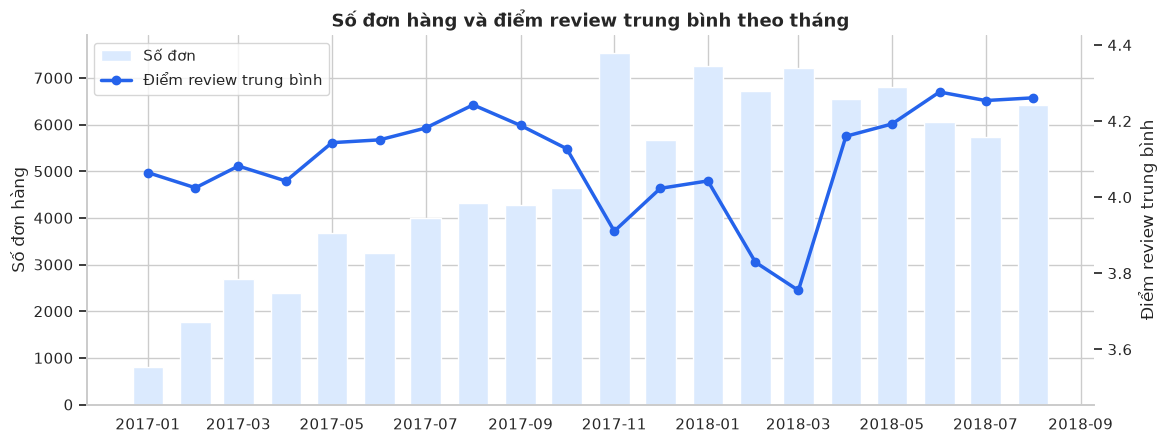

In [28]:
trend = q(f'''
    SELECT purchase_month, {CX_METRICS},
           avg(is_late) AS late_rate,
           avg(CASE WHEN is_delivered = 1 THEN delivery_days END) AS avg_delivery_days
    FROM order_cx
    WHERE {P.in_period}
    GROUP BY 1 ORDER BY 1''')

fig, ax1 = plt.subplots(figsize=(13, 4.8))
ax1.bar(trend.purchase_month, trend.orders, width=20, color="#DBEAFE", label="Số đơn")
ax1.set_ylabel("Số đơn hàng")
ax2 = ax1.twinx()
ax2.plot(trend.purchase_month, trend.avg_score, color=C_MAIN, marker="o", lw=2.5, label="Điểm review trung bình")
ax2.set_ylim(trend.avg_score.min() - 0.3, trend.avg_score.max() + 0.15); ax2.set_ylabel("Điểm review trung bình"); ax2.grid(False)
ax1.set_title("Số đơn hàng và điểm review trung bình theo tháng")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left"); plt.show()

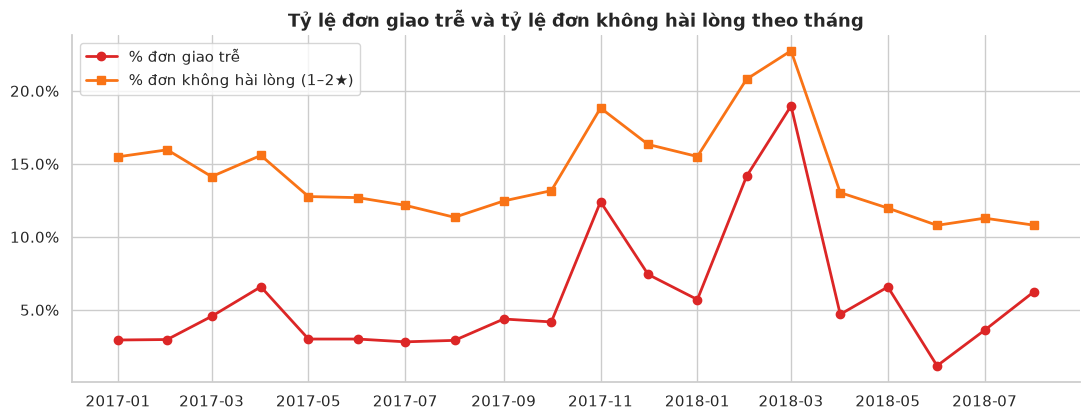

Tương quan theo tháng giữa % giao trễ và % không hài lòng: 0.861
                orders  avg_score  negative_rate  late_rate  avg_delivery_days
purchase_month                                                                
2017-01-01         799      4.065          0.155      0.029             12.084
2017-02-01        1777      4.025          0.160      0.030             12.621
2017-03-01        2681      4.082          0.141      0.046             12.398
2017-04-01        2380      4.042          0.156      0.066             14.380
2017-05-01        3685      4.143          0.128      0.030             10.768
2017-06-01        3240      4.151          0.127      0.030             11.483
2017-07-01        3994      4.182          0.122      0.028             11.153
2017-08-01        4328      4.243          0.113      0.029             10.705
2017-09-01        4272      4.188          0.125      0.044             11.401
2017-10-01        4631      4.127          0.132      0.042       

In [29]:
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(trend.purchase_month, trend.late_rate, color=C_BAD, marker="o", lw=2, label="% đơn giao trễ")
ax.plot(trend.purchase_month, trend.negative_rate, color=C_ORANGE, marker="s", lw=2, label="% đơn không hài lòng (1–2★)")
pct_axis(ax); ax.legend(); ax.set_title("Tỷ lệ đơn giao trễ và tỷ lệ đơn không hài lòng theo tháng")
plt.show()
print("Tương quan theo tháng giữa % giao trễ và % không hài lòng:",
      round(trend[["late_rate", "negative_rate"]].corr().iloc[0, 1], 3))
print(trend.set_index("purchase_month").round(3).to_string())

> **🔎 Kết quả chính**
> - Điểm TB **giảm rõ ở 11/2017 (3,91) và 02–03/2018 (3,83 → 3,76)**, đúng các tháng % giao trễ vọt lên 12,4%, 14,2%, 19,0%. Tương quan theo tháng giữa % trễ và % không hài lòng là **0,86** — hai đường trên visual của trang Khách hàng đi cùng nhau.
> - Từ 04/2018 số ngày giao giảm còn 7–11 ngày và điểm TB phục hồi lên **4,25–4,28**.

## 10. Trải nghiệm giao hàng
*Câu hỏi: "Giao hàng nhanh/chậm, đúng/trễ hạn liên quan đến điểm review mạnh đến mức nào?"*

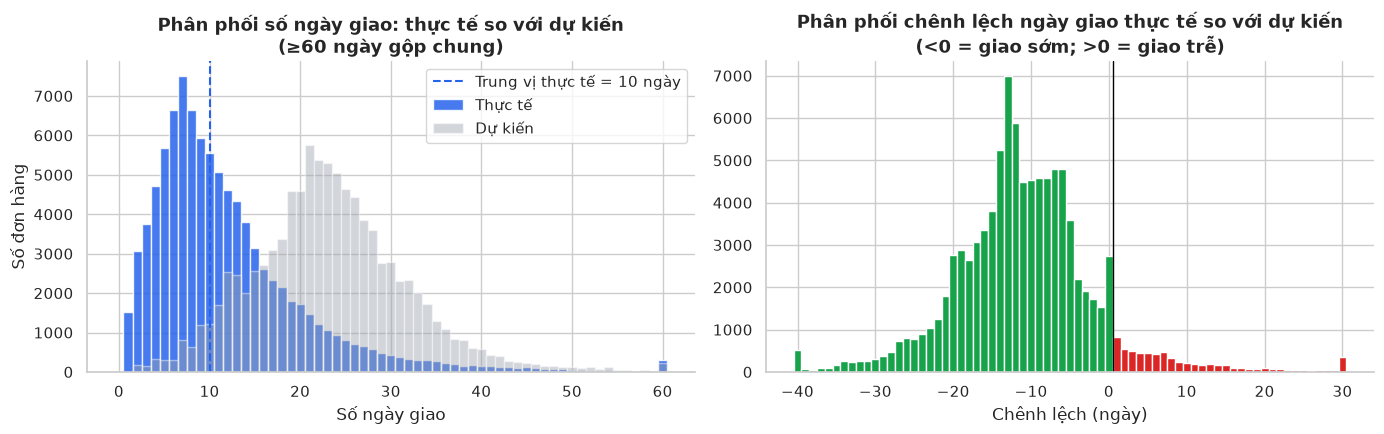

Trung vị số ngày giao sớm hơn dự kiến: 11.0


In [30]:
CLIP_DAYS = 60
h_actual = q(f"SELECT least(delivery_days, {CLIP_DAYS}) AS d, count(*) AS n FROM delivered GROUP BY 1 ORDER BY 1")
h_est = q(f"SELECT least(estimated_delivery_days, {CLIP_DAYS}) AS d, count(*) AS n FROM delivered GROUP BY 1 ORDER BY 1")
h_delay = q("SELECT greatest(least(delivery_delay_days, 30), -40) AS d, count(*) AS n FROM delivered GROUP BY 1 ORDER BY 1")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
ax1.bar(h_actual.d, h_actual.n, width=1, color=C_MAIN, alpha=0.85, label="Thực tế")
ax1.bar(h_est.d, h_est.n, width=1, color=C_GREY, alpha=0.45, label="Dự kiến")
ax1.axvline(kpi["median_delivery_days"], color=C_MAIN, ls="--",
            label=f"Trung vị thực tế = {kpi['median_delivery_days']:.0f} ngày")
ax1.legend(); ax1.set_title(f"Phân phối số ngày giao: thực tế so với dự kiến\n(≥{CLIP_DAYS} ngày gộp chung)")
ax1.set_xlabel("Số ngày giao"); ax1.set_ylabel("Số đơn hàng")
ax2.bar(h_delay.d, h_delay.n, width=1, color=np.where(h_delay.d > 0, C_BAD, C_GOOD))
ax2.axvline(0.5, color="black", lw=1)
ax2.set_title("Phân phối chênh lệch ngày giao thực tế so với dự kiến\n(<0 = giao sớm; >0 = giao trễ)"); ax2.set_xlabel("Chênh lệch (ngày)")
plt.tight_layout(); plt.show()
print("Trung vị số ngày giao sớm hơn dự kiến:", -q(f"SELECT {median_sql('delivery_delay_days')} AS m FROM delivered").m[0])

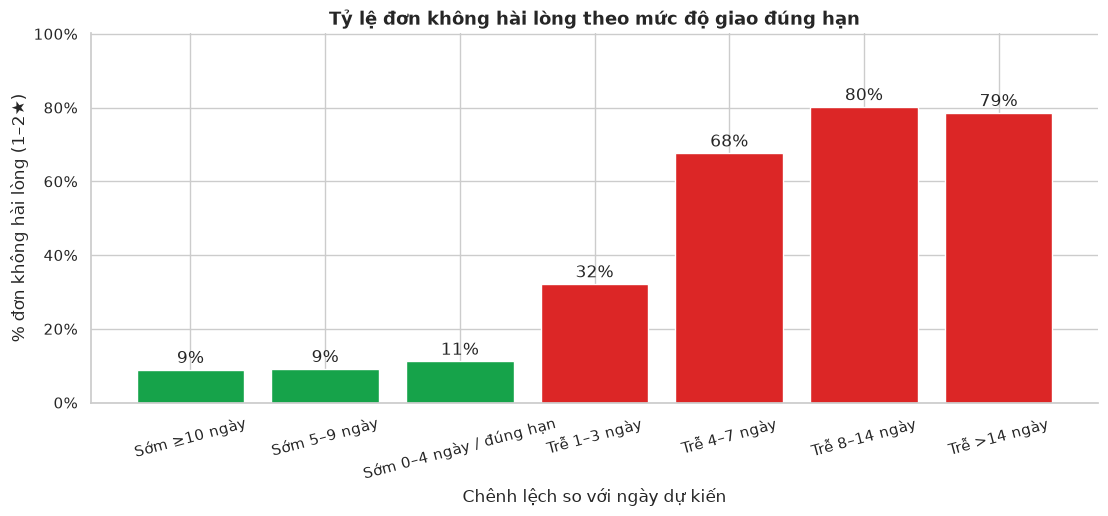

           delay_bucket  orders  avg_score  negative_rate  share_orders
           Sớm ≥10 ngày   55499      4.325          0.089         0.591
           Sớm 5–9 ngày   22140      4.279          0.092         0.236
Sớm 0–4 ngày / đúng hạn    9967      4.140          0.112         0.106
           Trễ 1–3 ngày    1829      3.293          0.321         0.019
           Trễ 4–7 ngày    1732      2.107          0.676         0.018
          Trễ 8–14 ngày    1438      1.673          0.802         0.015
           Trễ >14 ngày    1321      1.718          0.786         0.014


In [31]:
DELAY_BINS, DELAY_LAST = band_bins(GOLD.DELAY_BANDS)   # chênh lệch so với ngày dự kiến, giống delay_bucket của Gold
DELAY_ORDER = band_order(GOLD.DELAY_BANDS)
by_delay = ordered(q(f'''
    SELECT {band_sql("delivery_delay_days", DELAY_BINS, DELAY_LAST, upper_inclusive=True)} AS delay_bucket, {CX_METRICS}
    FROM reviewed_delivered GROUP BY 1'''), "delay_bucket", DELAY_ORDER)
by_delay["share_orders"] = by_delay.orders / by_delay.orders.sum()

fig, ax1 = plt.subplots(figsize=(13, 4.8))
bars = ax1.bar(by_delay.delay_bucket, by_delay.negative_rate,
               color=[C_GOOD if "Sớm" in b else C_BAD for b in by_delay.delay_bucket])
ax1.bar_label(bars, labels=[f"{v:.0%}" for v in by_delay.negative_rate], padding=2)
pct_axis(ax1); ax1.set_ylabel("% đơn không hài lòng (1–2★)"); ax1.set_ylim(0, by_delay.negative_rate.max() * 1.25)
ax1.set_title("Tỷ lệ đơn không hài lòng theo mức độ giao đúng hạn"); ax1.set_xlabel("Chênh lệch so với ngày dự kiến")
plt.setp(ax1.get_xticklabels(), rotation=15); plt.show()
print(by_delay.round(3).to_string(index=False))

- **Chú thích**: Dấu `*` trên đầu mỗi cột là số sao trung bình của các đơn trong nhóm đó

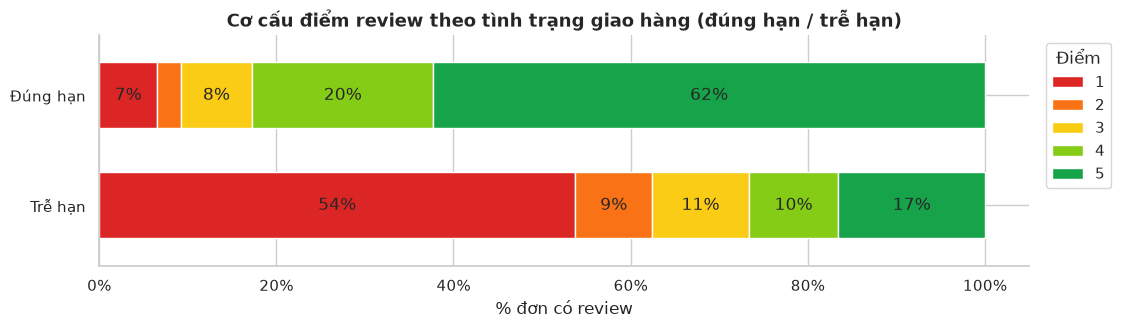

In [32]:
on_time = q('''SELECT CASE WHEN is_late = 1 THEN 'Trễ hạn' ELSE 'Đúng hạn' END AS delivery_status, score_int, count(*) AS n
               FROM reviewed_delivered GROUP BY 1, 2''')
pv = on_time.pivot(index="delivery_status", columns="score_int", values="n").fillna(0)
pv = pv.div(pv.sum(axis=1), axis=0)
ax = pv.plot(kind="barh", stacked=True, color=[SCORE_COLORS[c] for c in pv.columns], figsize=(12, 3), width=0.6)
for c in ax.containers:
    ax.bar_label(c, labels=[f"{v:.0%}" if v > 0.04 else "" for v in c.datavalues], label_type="center")
pct_axis(ax, "x"); ax.legend(title="Điểm", bbox_to_anchor=(1.01, 1)); ax.set_ylabel("")
ax.set_title("Cơ cấu điểm review theo tình trạng giao hàng (đúng hạn / trễ hạn)"); ax.set_xlabel("% đơn có review"); plt.show()

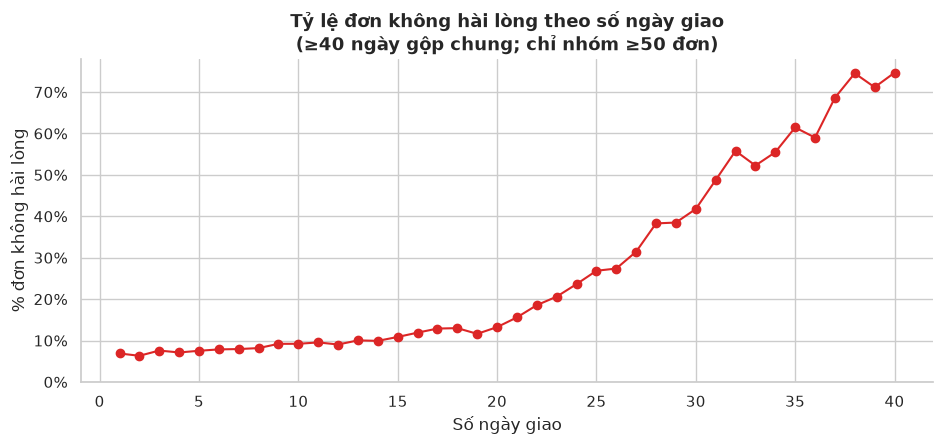

In [33]:
by_days = q(f'''SELECT least(delivery_days, 40) AS days, {CX_METRICS}
                FROM reviewed_delivered GROUP BY 1 HAVING count(*) >= 50 ORDER BY 1''')
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(by_days.days, by_days.negative_rate, marker="o", color=C_BAD)
pct_axis(ax); ax.set_ylim(0, None)
ax.set_title("Tỷ lệ đơn không hài lòng theo số ngày giao\n(≥40 ngày gộp chung; chỉ nhóm ≥50 đơn)"); ax.set_xlabel("Số ngày giao")
ax.set_ylabel("% đơn không hài lòng")
plt.show()

> **🔎 Kết quả chính**
> - Đây là phát hiện mạnh nhất: đơn giao **sớm / đúng hạn** có 9–11% không hài lòng; trễ 1–3 ngày lên **32%**; trễ 4–7 ngày **68%**; trễ ≥ 8 ngày **~80%** (điểm TB tụt từ 4,3 xuống 1,7).
> - Hệ thống hứa giao rất "an toàn" (trung vị giao sớm hơn hứa 11 ngày), nhưng 6,7% đơn trễ vẫn tạo ra phần lớn trải nghiệm xấu.

## 11. Đặc điểm đơn hàng & thanh toán
*Câu hỏi: "Đơn nhiều sản phẩm, nhiều người bán, phí ship cao, trả góp... có làm khách kém hài lòng hơn?"*

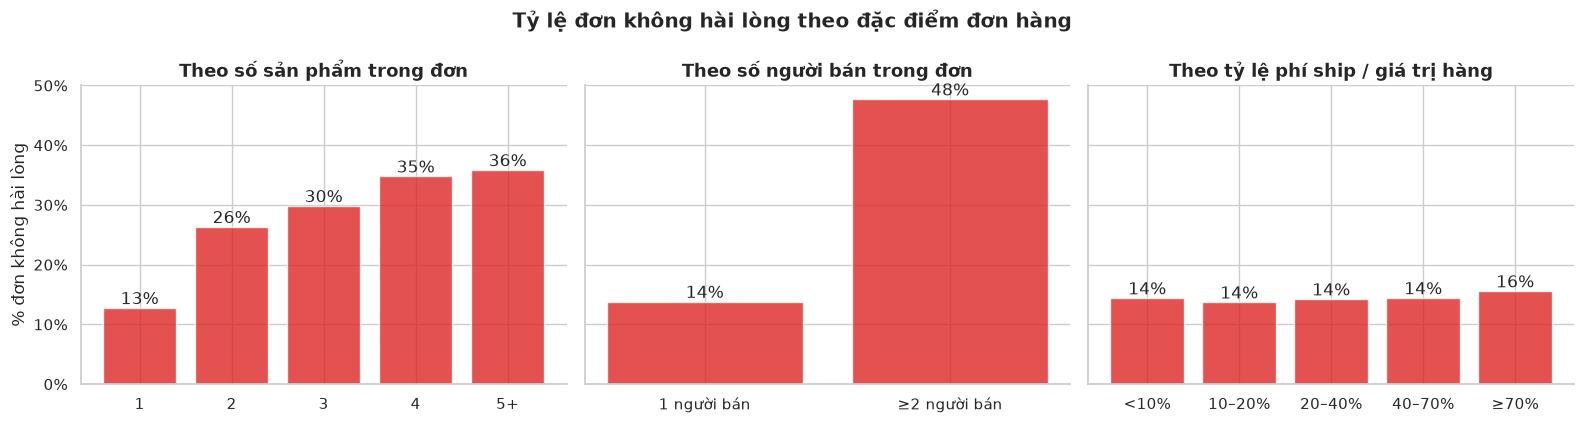

grp  orders  avg_score  negative_rate
  1   86518      4.159          0.127
  2    7270      3.657          0.263
  3    1278      3.514          0.298
  4     489      3.347          0.348
 5+     441      3.294          0.358 

         grp  orders  avg_score  negative_rate
 1 người bán   94794      4.120          0.138
≥2 người bán    1202      2.849          0.477 

   grp  orders  avg_score  negative_rate
  <10%   15330      4.136          0.144
10–20%   27547      4.125          0.137
20–40%   31135      4.099          0.142
40–70%   14501      4.081          0.144
  ≥70%    7483      4.033          0.155 



In [34]:
def driver_table(group_expr, order):
    return ordered(q(f"SELECT {group_expr} AS grp, {CX_METRICS} FROM reviewed WHERE n_items IS NOT NULL GROUP BY 1"),
                   "grp", order)

FREIGHT_BINS = [(0.1, "<10%"), (0.2, "10–20%"), (0.4, "20–40%"), (0.7, "40–70%")]
items_tbl = driver_table(band_sql("n_items", [(1, "1"), (2, "2"), (3, "3"), (4, "4")], "5+", upper_inclusive=True),
                         ["1", "2", "3", "4", "5+"])
sellers_tbl = driver_table(band_sql("n_sellers", [(1, "1 người bán")], "≥2 người bán", upper_inclusive=True),
                           ["1 người bán", "≥2 người bán"])
freight_tbl = driver_table(band_sql("freight_ratio", FREIGHT_BINS, "≥70%", upper_inclusive=True, null_label="n/a"),
                           [label for _, label in FREIGHT_BINS] + ["≥70%"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), sharey=True)
for ax, tbl, title in [(axes[0], items_tbl, "Theo số sản phẩm trong đơn"),
                       (axes[1], sellers_tbl, "Theo số người bán trong đơn"),
                       (axes[2], freight_tbl, "Theo tỷ lệ phí ship / giá trị hàng")]:
    b = ax.bar(tbl.grp, tbl.negative_rate, color=C_BAD, alpha=0.8)
    ax.bar_label(b, labels=[f"{v:.0%}" for v in tbl.negative_rate]); pct_axis(ax); ax.set_title(title)
axes[0].set_ylabel("% đơn không hài lòng")
plt.suptitle("Tỷ lệ đơn không hài lòng theo đặc điểm đơn hàng", fontweight="bold"); plt.tight_layout(); plt.show()
for t in (items_tbl, sellers_tbl, freight_tbl):
    print(t.round(3).to_string(index=False), "\n")

In [35]:
pay_tbl = q(f'''SELECT payment_type, {CX_METRICS}, avg(payment_value) AS avg_order_value
                FROM reviewed WHERE payment_type IS NOT NULL AND n_items IS NOT NULL GROUP BY 1 ORDER BY orders DESC''')
INST_BINS = [(1, "1 kỳ"), (3, "2–3 kỳ"), (6, "4–6 kỳ"), (10, "7–10 kỳ")]
inst_tbl = ordered(q(f'''
    SELECT {band_sql("installments", INST_BINS, ">10 kỳ", upper_inclusive=True)} AS grp, {CX_METRICS}, avg(payment_value) AS avg_order_value
    FROM reviewed WHERE payment_type = 'credit_card' AND n_items IS NOT NULL GROUP BY 1'''), "grp", [label for _, label in INST_BINS] + [">10 kỳ"])
print(pay_tbl.round(3).to_string(index=False), "\n")
print(inst_tbl.round(3).to_string(index=False))

payment_type  orders  avg_score  negative_rate  avg_order_value
 credit_card   72493      4.104          0.143          167.056
      boleto   19070      4.106          0.139          144.865
     voucher    2969      4.075          0.150          114.527
  debit_card    1463      4.190          0.126          141.723 

    grp  orders  avg_score  negative_rate  avg_order_value
   1 kỳ   23296      4.172          0.126          100.702
 2–3 kỳ   21886      4.096          0.143          135.937
 4–6 kỳ   15602      4.076          0.149          182.842
7–10 kỳ   11384      4.023          0.169          335.895
 >10 kỳ     325      3.902          0.203          346.959


> **🔎 Kết quả chính**
> - Đơn càng nhiều sản phẩm / người bán càng dễ bất mãn: 1 sản phẩm 12,7% không hài lòng, 2 sản phẩm 26,3%, ≥ 5 sản phẩm 35,8%; đơn **≥ 2 người bán 47,7%** (giao tách kiện).
> - Tỷ lệ phí ship / giá trị hàng (13,7–15,5%) và hình thức thanh toán (12,6–15,0%) gần như **không** tạo khác biệt.
> - Trả góp nhiều kỳ có % không hài lòng cao hơn (1 kỳ 12,6% → > 10 kỳ 20,3%), nhiều khả năng do đi kèm sản phẩm đắt / cồng kềnh, không phải do bản thân việc trả góp.

## 12. Trải nghiệm đơn đầu có liên quan đến việc quay lại?
*Câu hỏi: "Khách có đơn đầu tiên tốt có quay lại nhiều hơn không?"* (Phân bố số đơn / khách và cohort giữ chân xem §7.)

Dùng tỷ lệ **mua lại trong 90 ngày** sau đơn đầu, chỉ với khách có đơn đầu trước `ngày cuối dữ liệu − 90 ngày`, để các nhóm khách
được theo dõi cùng một khoảng thời gian.

Mốc cuối dữ liệu: 2018-10-17 17:30:18


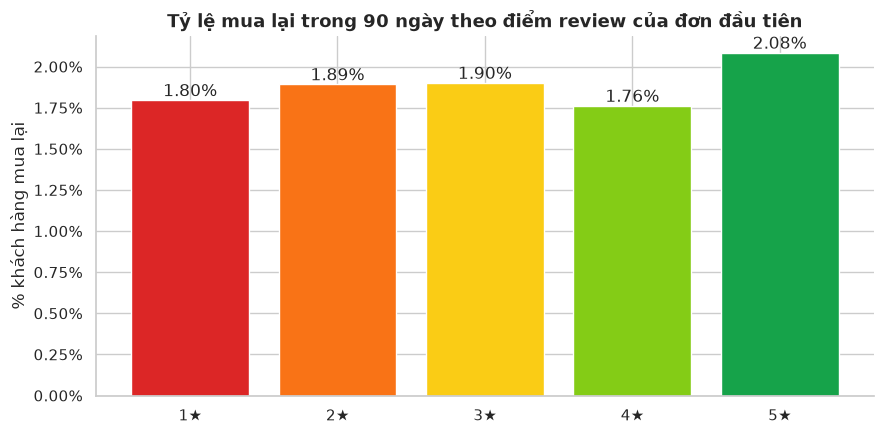

 score_int  customers  repurchase_rate
         1      10075           0.0180
         2       2747           0.0189
         3       7151           0.0190
         4      16514           0.0176
         5      48394           0.0208 

  first_delivery  customers  repurchase_rate
Đơn đầu đúng hạn      77328           0.0223
 Đơn đầu trễ hạn       5837           0.0197


In [36]:
REPURCHASE_WINDOW_DAYS = GOLD.REPURCHASE_WINDOW_DAYS   # = repurchase_90d của Gold
# Mốc cuối dữ liệu: chỉ xét khách có đơn đầu cách mốc này ≥ REPURCHASE_WINDOW_DAYS ngày (đủ thời gian quan sát mua lại)
DATA_END = q("SELECT max(order_purchase_timestamp) AS t FROM order_cx").t.iloc[0]
print(f"Mốc cuối dữ liệu: {DATA_END:%Y-%m-%d %H:%M:%S}")
con.execute(f'''
CREATE OR REPLACE TABLE first_orders AS
WITH ranked AS (
    SELECT *, row_number() OVER w AS rn, lead(order_purchase_timestamp) OVER w AS next_purchase
    FROM order_cx
    WINDOW w AS (PARTITION BY customer_key ORDER BY order_purchase_timestamp, order_key))
SELECT *,
       CAST((next_purchase IS NOT NULL
        AND next_purchase <= order_purchase_timestamp + INTERVAL '{REPURCHASE_WINDOW_DAYS}' DAY) AS INTEGER) AS repurchase_90d
FROM ranked
WHERE rn = 1
  AND order_purchase_timestamp <= TIMESTAMP '{DATA_END}' - INTERVAL '{REPURCHASE_WINDOW_DAYS}' DAY
''')

by_first_score = q('''SELECT score_int, count(*) AS customers, avg(repurchase_90d) AS repurchase_rate
                      FROM first_orders WHERE score_int IS NOT NULL GROUP BY 1 ORDER BY 1''')
by_first_late = q('''SELECT CASE WHEN is_late = 1 THEN 'Đơn đầu trễ hạn' ELSE 'Đơn đầu đúng hạn' END AS first_delivery,
                            count(*) AS customers, avg(repurchase_90d) AS repurchase_rate
                     FROM first_orders WHERE is_late IS NOT NULL GROUP BY 1''')

fig, ax = plt.subplots(figsize=(9, 4.5))
b = ax.bar(by_first_score.score_int.astype(str) + "★", by_first_score.repurchase_rate,
           color=[SCORE_COLORS[s] for s in by_first_score.score_int])
ax.bar_label(b, labels=[f"{v:.2%}" for v in by_first_score.repurchase_rate]); pct_axis(ax)
ax.set_title(f"Tỷ lệ mua lại trong {REPURCHASE_WINDOW_DAYS} ngày theo điểm review của đơn đầu tiên")
ax.set_ylabel("% khách hàng mua lại")
plt.tight_layout(); plt.show()
print(by_first_score.round(4).to_string(index=False), "\n")
print(by_first_late.round(4).to_string(index=False))

> **🔎 Kết quả chính**
> - Tỷ lệ mua lại trong 90 ngày chỉ ~2% và **gần như không đổi theo điểm đơn đầu** (1★: 1,80% · 5★: 2,08%) hay theo giao đúng / trễ hạn (2,23% so với 1,97%).
> - → Trải nghiệm đơn đầu **không** quyết định việc quay lại. Giả định "khách nhận đơn đầu đúng hạn quay lại gấp 3 lần" **không được dữ liệu ủng hộ**; giữ chân cần đòn bẩy khác (CRM, khuyến mãi, thành viên).

## 13. Tổng hợp — yếu tố nào gắn với đơn không hài lòng nhiều nhất?
So sánh % đơn không hài lòng giữa *nhóm có yếu tố* và *nhóm không có*, **trong cùng một tập đơn phù hợp**:
yếu tố giao hàng chỉ so trong các đơn đã giao; các yếu tố khác so trong mọi đơn có review. Đây là so sánh mô tả, không phải bằng chứng nhân quả.

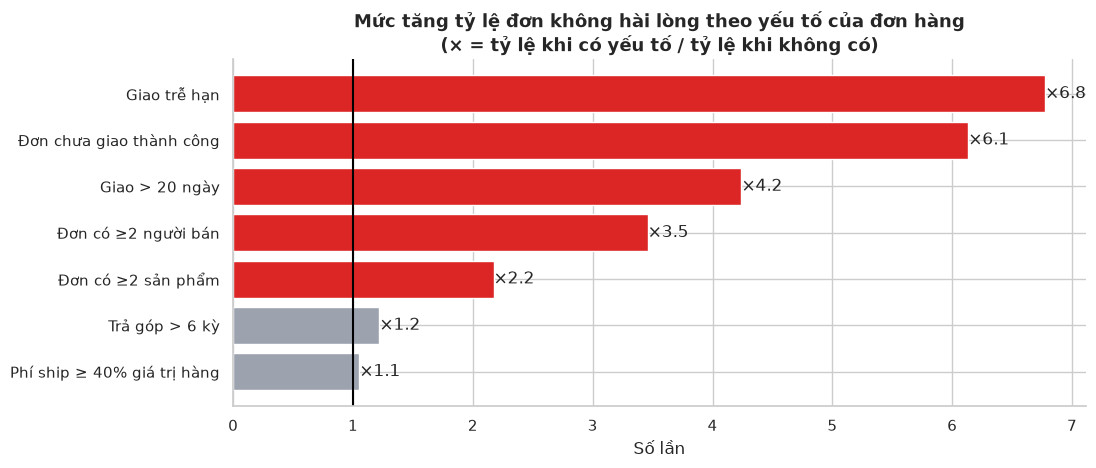

                     Yếu tố  % đơn có yếu tố  % không hài lòng (có)  % không hài lòng (không)  Gấp (lần)
               Giao trễ hạn            0.067                  0.625                     0.092      6.775
   Đơn chưa giao thành công            0.029                  0.786                     0.128      6.134
             Giao > 20 ngày            0.130                  0.383                     0.090      4.241
        Đơn có ≥2 người bán            0.013                  0.477                     0.138      3.459
         Đơn có ≥2 sản phẩm            0.099                  0.277                     0.127      2.172
             Trả góp > 6 kỳ            0.122                  0.175                     0.143      1.220
Phí ship ≥ 40% giá trị hàng            0.229                  0.148                     0.140      1.053


In [37]:
FACTORS = [  # (tên yếu tố, điều kiện SQL, tập đơn để so sánh)
    ("Giao trễ hạn", "is_late = 1", "reviewed_delivered"),
    ("Giao > 20 ngày", "delivery_days > 20", "reviewed_delivered"),
    ("Đơn chưa giao thành công", "is_delivered = 0", "reviewed"),
    ("Đơn có ≥2 người bán", "n_sellers >= 2", "reviewed"),
    ("Đơn có ≥2 sản phẩm", "n_items >= 2", "reviewed"),
    ("Phí ship ≥ 40% giá trị hàng", "freight_ratio >= 0.4", "reviewed"),
    ("Trả góp > 6 kỳ", "installments > 6", "reviewed"),
]
drivers = pd.concat([q(f'''
    SELECT '{name}' AS "Yếu tố",
           avg(CAST(({cond}) AS INTEGER)) AS "% đơn có yếu tố",
           avg(CASE WHEN {cond} THEN is_negative END) AS "% không hài lòng (có)",
           avg(CASE WHEN NOT ({cond}) THEN is_negative END) AS "% không hài lòng (không)"
    FROM {population} WHERE ({cond}) IS NOT NULL''') for name, cond, population in FACTORS])
drivers["Gấp (lần)"] = drivers["% không hài lòng (có)"] / drivers["% không hài lòng (không)"].replace(0, np.nan)
drivers = drivers.dropna(subset=["Gấp (lần)"]).sort_values("Gấp (lần)", ascending=False)

fig, ax = plt.subplots(figsize=(11, 4.5))
b = ax.barh(drivers["Yếu tố"], drivers["Gấp (lần)"], color=[C_BAD if v >= 1.5 else C_GREY for v in drivers["Gấp (lần)"]])
ax.bar_label(b, fmt="×%.1f"); ax.axvline(1, color="black"); ax.invert_yaxis()
ax.set_title("Mức tăng tỷ lệ đơn không hài lòng theo yếu tố của đơn hàng\n(× = tỷ lệ khi có yếu tố / tỷ lệ khi không có)"); ax.set_xlabel("Số lần"); plt.show()
print(drivers.round(3).to_string(index=False))

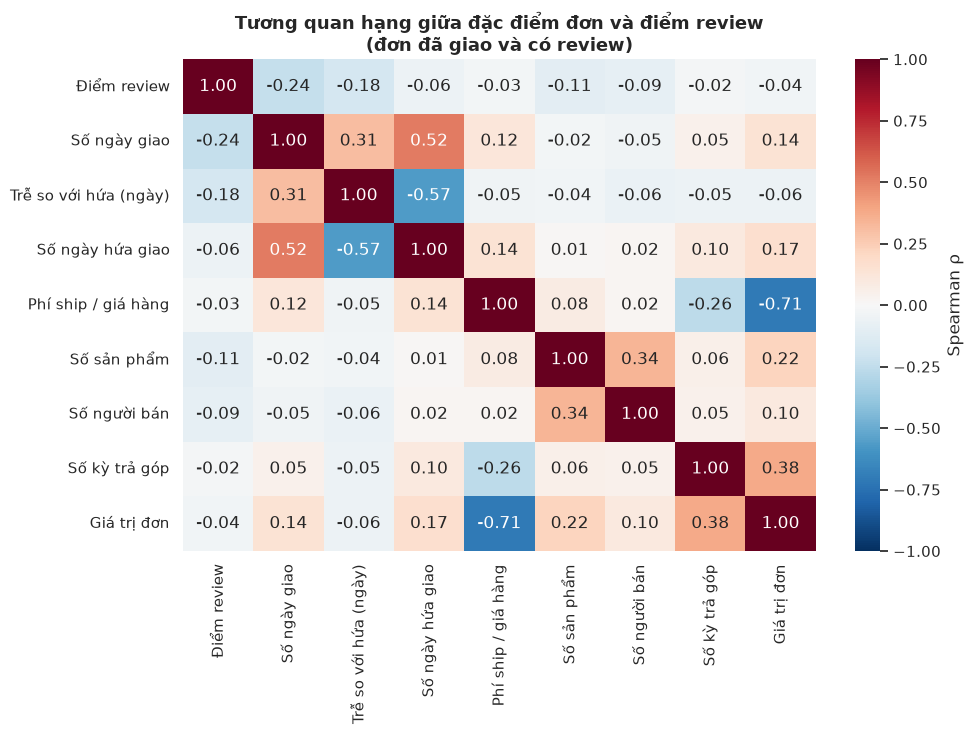

Số ngày giao            -0.236
Trễ so với hứa (ngày)   -0.179
Số sản phẩm             -0.106
Số người bán            -0.093
Số ngày hứa giao        -0.055
Giá trị đơn             -0.039
Phí ship / giá hàng     -0.031
Số kỳ trả góp           -0.020


In [38]:
# Tương quan hạng (Spearman) giữa đặc điểm đơn và điểm review — đơn đã giao & có review
corr_cols = {"review_score": "Điểm review", "delivery_days": "Số ngày giao", "delivery_delay_days": "Trễ so với hứa (ngày)",
             "estimated_delivery_days": "Số ngày hứa giao", "freight_ratio": "Phí ship / giá hàng", "n_items": "Số sản phẩm",
             "n_sellers": "Số người bán", "installments": "Số kỳ trả góp", "gmv": "Giá trị đơn"}
cdf = q(f"SELECT {', '.join(corr_cols)} FROM reviewed_delivered WHERE n_items IS NOT NULL").rename(columns=corr_cols)
cm = cdf.corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 7.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "Spearman ρ"})
ax.set_title("Tương quan hạng giữa đặc điểm đơn và điểm review\n(đơn đã giao và có review)")
plt.tight_layout(); plt.show()
print(cm["Điểm review"].drop("Điểm review").sort_values().round(3).to_string())

> **🔎 Kết quả chính**
> - Xếp hạng theo mức tăng % không hài lòng: **giao trễ hạn ×6,8** (62,5% so với 9,2%) > **đơn chưa giao thành công ×6,1** > **giao > 20 ngày ×4,2** > **đơn ≥ 2 người bán ×3,5** > đơn ≥ 2 sản phẩm ×2,2.
> - Trả góp > 6 kỳ (×1,2) và phí ship cao (×1,05) gần như không đáng kể. Tương quan hạng với điểm review cũng xếp **số ngày giao (−0,24)** và **trễ so với hứa (−0,18)** đứng đầu; giá trị đơn, phí ship, trả góp ≈ 0.
> - Ưu tiên cải thiện: **đúng hạn giao hàng** và **gộp kiện cho đơn nhiều người bán / nhiều sản phẩm**.

## 14. Chương trình kích hoạt đơn thứ hai — tệp khách đủ điều kiện
*Câu hỏi: "Có nên duyệt chương trình kích cầu / chăm sóc khách mới? Nếu có thì nhắm vào bao nhiêu khách?"*

Chỉ đưa **bằng chứng mô tả**, không dựng mô hình doanh thu:
- **Tệp đủ điều kiện** = khách mới chỉ có 1 đơn hợp lệ và đơn đó nằm trong `GOLD.REPURCHASE_WINDOW_DAYS` ngày cuối của dữ liệu
  (vẫn còn trong cửa sổ quay lại tính tới ngày chốt số liệu) — đúng nhóm "Khách mới" mà §3 khuyên kích hoạt đơn thứ 2.
- **Mức nền** = tỷ lệ khách mua lại trong 90 ngày của các cohort đã đủ thời gian quan sát (§12), để biết chương trình phải vượt mức nào mới có ý nghĩa.

In [39]:
eligible = q(f"""
    SELECT count(*) AS customers, avg(monetary) AS first_order_value, sum(monetary) AS first_order_gmv
    FROM cust_base
    WHERE frequency = 1 AND first_purchase > TIMESTAMP '{SNAPSHOT}' - INTERVAL '{REPURCHASE_WINDOW_DAYS}' DAY""").iloc[0]
base_rate = scalar("SELECT avg(repurchase_90d) FROM first_orders")
seg_new = scalar("SELECT count(*) FROM customer_rfm WHERE segment = 'Khách mới'")
second = q("""SELECT avg(gmv) AS aov_2nd FROM orders_valid WHERE order_seq = 2""").iloc[0]
print(f"Ngày chốt số liệu: {SNAPSHOT} | cửa sổ: {REPURCHASE_WINDOW_DAYS} ngày")
print(f"Tệp khách đủ điều kiện (1 đơn, đơn đầu trong {REPURCHASE_WINDOW_DAYS} ngày cuối): {eligible.customers:,.0f} khách "
      f"(giá trị đơn đầu TB {eligible.first_order_value:,.0f} BRL)")
print(f"So với phân khúc RFM 'Khách mới' (R ≥ 4, ~6 tháng gần nhất): {seg_new:,} khách")
print(f"Mức nền: {base_rate:.2%} khách quay lại trong {REPURCHASE_WINDOW_DAYS} ngày (cohort đã đủ thời gian quan sát)")
print(f"→ Nếu giữ nguyên mức nền, tệp này chỉ sinh khoảng {eligible.customers * base_rate:,.0f} đơn thứ hai; AOV của đơn thứ hai trong lịch sử = {second.aov_2nd:,.0f} BRL")

Ngày chốt số liệu: 2018-09-04 | cửa sổ: 90 ngày
Tệp khách đủ điều kiện (1 đơn, đơn đầu trong 90 ngày cuối): 16,353 khách (giá trị đơn đầu TB 163 BRL)
So với phân khúc RFM 'Khách mới' (R ≥ 4, ~6 tháng gần nhất): 36,342 khách
Mức nền: 2.24% khách quay lại trong 90 ngày (cohort đã đủ thời gian quan sát)
→ Nếu giữ nguyên mức nền, tệp này chỉ sinh khoảng 367 đơn thứ hai; AOV của đơn thứ hai trong lịch sử = 146 BRL


> **🔎 Kết quả chính**
> - **Tệp đủ điều kiện: 16.353 khách** mua lần đầu trong 90 ngày cuối và chưa quay lại (đơn đầu TB 163 BRL) — nhỏ hơn nhiều so với 36.342 khách của phân khúc "Khách mới" (6 tháng).
> - **Mức nền chỉ 2,24%** quay lại trong 90 ngày → nếu không làm gì, tệp này sinh khoảng **370 đơn thứ hai** (AOV lịch sử của đơn thứ hai ≈ 146 BRL).
> - Hàm ý cho HĐQT: có cơ sở để duyệt chương trình **thử nghiệm có nhóm đối chứng** trên tệp 16 nghìn khách, đo theo mức nền 2,24%. Vì trải nghiệm đơn đầu không kéo được khách quay lại (§12), đòn bẩy phải là ưu đãi / CRM, gửi trong 1–3 tháng sau đơn đầu (§7), vào chiều–tối ngày thường (§4), qua thẻ tín dụng (§6).

## 15. Đối chiếu với Gold (nguồn của Power BI)
Thẻ KPI của trang Khách hàng (kỳ này) khớp `fact_order_summary`; phân khúc RFM và khoảng cách tới đơn thứ hai khớp `dim_customer_profile`
(nguồn của view `customer_rfm` và bảng `cust_2nd_gap` trên Power BI).

In [40]:
G, GP = "iceberg.gold.fact_order_summary", "iceberg.gold.dim_customer_profile"
gcur = gold_period_where(P.cur)
k = cust_kpis(P.cur)
seg_eda = q("SELECT segment, count(*) AS n FROM customer_rfm GROUP BY 1").set_index("segment").n
checks = [
    ("Tổng số khách hàng (kỳ này)", k["customers"], f"SELECT count(DISTINCT customer_key) FROM {G} WHERE is_valid = 1 AND {gcur}"),
    ("Giá trị TB đơn (kỳ này)", k["aov"], f"SELECT avg(order_gmv) FROM {G} WHERE is_valid = 1 AND {gcur}"),
    ("Số item TB mỗi đơn (kỳ này)", k["items_per_order"], f"SELECT avg(CAST(n_items AS DOUBLE)) FROM {G} WHERE is_valid = 1 AND {gcur}"),
    ("Tỷ lệ khách mua lại (kỳ này)", k["repeat_rate"],
     f"SELECT avg(CAST(n >= 2 AS DOUBLE)) FROM (SELECT customer_key, count(*) AS n FROM {G} WHERE is_valid = 1 AND {gcur} GROUP BY 1)"),
    ("Khách có RFM", seg_eda.sum(), f"SELECT count(*) FROM {GP} WHERE frequency > 0"),
    ("Khách có đơn thứ 2", scalar("SELECT count(*) FROM cust_base WHERE days_to_2nd_order IS NOT NULL"),
     f"SELECT count(*) FROM {GP} WHERE days_to_2nd IS NOT NULL"),
]
checks += [(f"RFM: {s}", seg_eda.get(s, 0), f"SELECT count(*) FROM {GP} WHERE frequency > 0 AND segment = '{s}'") for s in SEG_ORDER]
reconcile(checks)

,EDA (Silver),Gold,Sai lệch,Khớp
Chỉ số,,,,
Tổng số khách hàng (kỳ này),"51,098","51,098",0.00e+00,True
Giá trị TB đơn (kỳ này),160.7201,160.7201,1.77e-16,True
Số item TB mỗi đơn (kỳ này),1.1422,1.1422,0.00e+00,True
Tỷ lệ khách mua lại (kỳ này),0.0210,0.0210,0.00e+00,True
Khách có RFM,"93,664","93,664",0.00e+00,True
Khách có đơn thứ 2,"2,830","2,830",0.00e+00,True
RFM: Champions,"1,216","1,216",0.00e+00,True
RFM: Loyal - cần giữ chân,"1,614","1,614",0.00e+00,True
RFM: Khách mới,"36,342","36,342",0.00e+00,True


## 16. Đánh giá & tuyển chọn visual cho trang Khách hàng
Tiêu chí đưa lên Power BI: đọc hiểu trong ~10 giây, dẫn tới quyết định ③ (nhắm nhóm nào, có duyệt chương trình không), còn đúng khi lọc bằng slicer.

| Biểu đồ EDA | Câu hỏi / quyết định | Visual Power BI tương ứng hoặc "Phụ lục" | Lý do |
|---|---|---|---|
| §1 Bảng KPI khách hàng | Quy mô và giá trị khách | Thẻ *Tổng số khách hàng*, *Giá trị trung bình đơn*, *Số item TB mỗi đơn*, *Tỷ lệ khách hàng mua lại* | Bốn con số trả lời "khách là ai, mua bao nhiêu" |
| §3 RFM | Nhắm nhóm nào | Trang p1 *Phân khúc RFM* | Đặt ở trang tổng quan để nối thẳng sang quyết định ③ |
| §4 Heatmap thứ × giờ | Khi nào nên chạy chiến dịch | *Số đơn theo thứ và giờ đặt hàng* | Khung giờ vàng thấy ngay; tỷ trọng theo thứ/giờ, số đơn theo ngày để phụ lục |
| §6 Hình thức thanh toán | Khách trả bằng gì | *Hình thức thanh toán (% số đơn)* | Thẻ tín dụng áp đảo → kênh khuyến mãi |
| §6 Số kỳ trả góp × AOV | Trả góp có kéo giá trị đơn không | *Số kỳ trả góp và giá trị đơn trung bình* | Đòn bẩy cho đơn giá trị cao |
| §7 Khoảng cách tới đơn thứ 2 | Khi nào nhắc khách quay lại | *Khoảng thời gian từ đơn đầu tiên tới đơn thứ hai* | Căn cứ cho cửa sổ chương trình (§14) |
| §9 % giao trễ và % không hài lòng theo tháng | Trải nghiệm tốt lên hay xấu đi | *Tỷ lệ đơn giao trễ và tỷ lệ đơn không hài lòng* | Hai đường đi cùng nhau → giao hàng là nguyên nhân chính |
| §2 Khách mới / quay lại theo tháng, §7 cohort, ngành đơn đầu | Tăng trưởng từ khách mới hay cũ | Phụ lục | Kết luận "sàn sống nhờ khách mới" đã thể hiện qua thẻ tỷ lệ mua lại |
| §5 Giá trị đơn, số sản phẩm / đơn | Giỏ hàng điển hình | Phụ lục (thẻ *Số item TB mỗi đơn*) | |
| §8 Phân bố sao, bình luận | Mức hài lòng | Phụ lục | |
| §10 % không hài lòng theo nấc trễ, §11–§13 yếu tố, tương quan | Vì sao khách không hài lòng | Phụ lục | Bằng chứng khi HĐQT hỏi "tại sao review giảm" |
| §12 Đơn đầu → quay lại, §14 tệp đủ điều kiện | Có duyệt chương trình không | Phụ lục; số liệu đưa vào tờ trình | Quyết định cần con số, không cần thêm biểu đồ |

In [41]:
con.close()